In [1]:
%load_ext autoreload
%autoreload 2

from IPython.display import display
import os
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import matplotlib.colors as mcolors
import matplotlib.markers as mmarkers
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib as mpl
import seaborn as sns
import scipy
import json
from scipy.stats import spearmanr
from sklearn.manifold import MDS
from tqdm.notebook import tqdm

from compcats.localizer import localizer
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils, misc_utils, responsecomparison_utils as rcutils

import main_analysis as ma
import paths

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
from matplotlib.font_manager import FontProperties
rcParams.update({
    'figure.autolayout': False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial"],
    })
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

# /System/Library/Fonts/Avenir.ttc

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/preprint'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR

# Device
DEVICE = misc_utils.get_device()

pixdim[1,2,3] should be non-zero; setting 0 dims to 1


# Main figure

## 3b: Boxplots

In [4]:
tthreshold = 7
frois = ['FFA', 'EBA', 'PPA']
model_localizer = 'grillspector'
froi_comparisons = {
    'FFA': ['OFA', 'EBA', 'PPA'],
    'EBA': ['FBA', 'FFA', 'PPA'],
    'PPA': ['OPA', 'RSC', 'FFA'],
}

FROIFROI_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/froifroi_correlations_nsd515.csv'
SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/modelsubject_correlations_nsd515.csv'

taskoptimized_model_names = ma.get_model_names('task_optimized')

### Alternative: Median per subject for brain-brain ceiling

In [ ]:
savefig = True

plot_dir = f'{PLOTS_DIR}/section2_3/main_figure/individual_plots'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'EBA', 'PPA']
subjects = list(range(1, 9)) # subject IDs are 1-indexed in the CSV
models = taskoptimized_model_names

hh_color = 'red'
mh_color = 'blue'
colors = [hh_color, mh_color]

metrics = ['normed_pearsonr', 'normed_rdmr']
metric_ylims = {
    'normed_pearsonr': (0, 1.15),
    'normed_rdmr': (0, 1.4),
}

fig, axs = plt.subplots(
    len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300
)

for midx, metric in enumerate(metrics):
    print('\n' + metric)
    # fig, ax = plt.figure(figsize=(5, 5), dpi=300)
    for fidx, froi in enumerate(frois):
        print(froi)
        ax_current = axs[midx, fidx]
        hh_medians = []
        for subject in subjects:
            subjectsubject_froi = subjectsubject_correlations_csv[
                (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
                (
                    (subjectsubject_correlations_csv['subject1'] == subject) | 
                    (subjectsubject_correlations_csv['subject2'] == subject)
                )
            ][metric]
            hh_medians.append(subjectsubject_froi.median())
        hh_medians = np.array(hh_medians).flatten()

        mh_medians, mh_sems = [], []
        for model in models:
            modelsubject_froi = modelsubject_correlations_csv[
                (modelsubject_correlations_csv['fmri_froi'] == froi) &
                (modelsubject_correlations_csv['model_name'] == model) &
                (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_localizer'] == model_localizer)
            ]
            mh_medians.append(modelsubject_froi[metric].median())
            mh_sems.append(modelsubject_froi[metric].sem())
        mh_medians = np.array(mh_medians)
        mh_sems = np.array(mh_sems)

        jitter_scale = 0.01 #0.05
        scatter_pad = 0 # 0.05
        alpha = 0.75 # 0.5
        markersize = 15 # 25

        bar_positions = np.array([0, 0.5])

        # y=0 line
        ax_current.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

        # Box plot
        box_data = [hh_medians, mh_medians]
        linewidth = 0.75
        barwidth = 0.25 # 0.35
        boxes = ax_current.boxplot(
                    box_data, positions=bar_positions, patch_artist=True, 
                    widths=barwidth, showfliers=False,
                    boxprops={'color': 'black', 'linewidth': linewidth},
                    whiskerprops=dict(linewidth=linewidth),
                    capprops=dict(linewidth=linewidth),
                    medianprops={'color': 'black', 'linewidth': linewidth},
                    flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
                )
        for i, data in enumerate(box_data):
            med = np.median(data)
            # Manually draw a longer median line
            x = bar_positions[i]  # X-position of the boxplot
            # 0.225
            ax_current.plot([x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
        
        # Color the boxes according to category colors
        for box, color in zip(boxes['boxes'], colors):
            box.set(facecolor=color)

        x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
        x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
        x_subjectsubject += scatter_pad
        x_modelsubject += scatter_pad
        ax_current.scatter(
            x_subjectsubject, hh_medians, color='gray', alpha=alpha, label='Subject-Subject', zorder=5,
            edgecolors='none', s=markersize
        )
        ax_current.scatter(
            x_modelsubject, mh_medians, color='gray', alpha=alpha, label='Model-Subject', zorder=5,
            edgecolors='none', s=markersize
        )
        print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
        print(f'Number of Model-Subject correlations: {len(mh_medians)}')
        
        # Conduct Welch's t-test
        t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
        ax_current.set_xticks(bar_positions)
        print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')
        
        # Write froi name in bottom left corner
        ax_current.text(0.05, 0.25, froi, transform=ax_current.transAxes, fontsize=12, verticalalignment='top')

        ax_current.spines['top'].set_visible(False)
        ax_current.spines['right'].set_visible(False)
        ax_current.spines['left'].set_position(('outward', 5))
        ax_current.spines['bottom'].set_position(('outward', 5))
        ax_current.set_yticks([0, 0.25, 0.5, 0.75, 1])
        ax_current.spines['left'].set_bounds(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        ax_current.set_ylim(metric_ylims[metric])
        ax_current.spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
        ax_current.set_xlim(bar_positions[0]-0.25, bar_positions[1]+0.25)
        ax_current.tick_params(axis='x', labelbottom=False)

        if froi != 'FFA':
            ax_current.spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            ax_current.yaxis.set_ticks([])

if savefig:
    plt.savefig(f'{plot_dir}/fig3b_boxplots.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()


normed_pearsonr
FFA
Number of Subject-Subject correlations: 8
Number of Model-Subject correlations: 35
t-value: 21.76, p-value: 1.77e-22
PPA
Number of Subject-Subject correlations: 8
Number of Model-Subject correlations: 35
t-value: 20.67, p-value: 2.93e-20
EBA
Number of Subject-Subject correlations: 8
Number of Model-Subject correlations: 35
t-value: 17.97, p-value: 1.41e-17

normed_rdmr
FFA
Number of Subject-Subject correlations: 8
Number of Model-Subject correlations: 35
t-value: 21.37, p-value: 6.84e-15
PPA
Number of Subject-Subject correlations: 8
Number of Model-Subject correlations: 35
t-value: 20.92, p-value: 3.03e-11
EBA
Number of Subject-Subject correlations: 8
Number of Model-Subject correlations: 35
t-value: 21.89, p-value: 5.20e-13


## Legacy: 28 brain-brain points


normed_pearsonr
FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 22.58, p-value: 1.06e-28
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 21.38, p-value: 1.73e-29
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 19.57, p-value: 1.19e-26


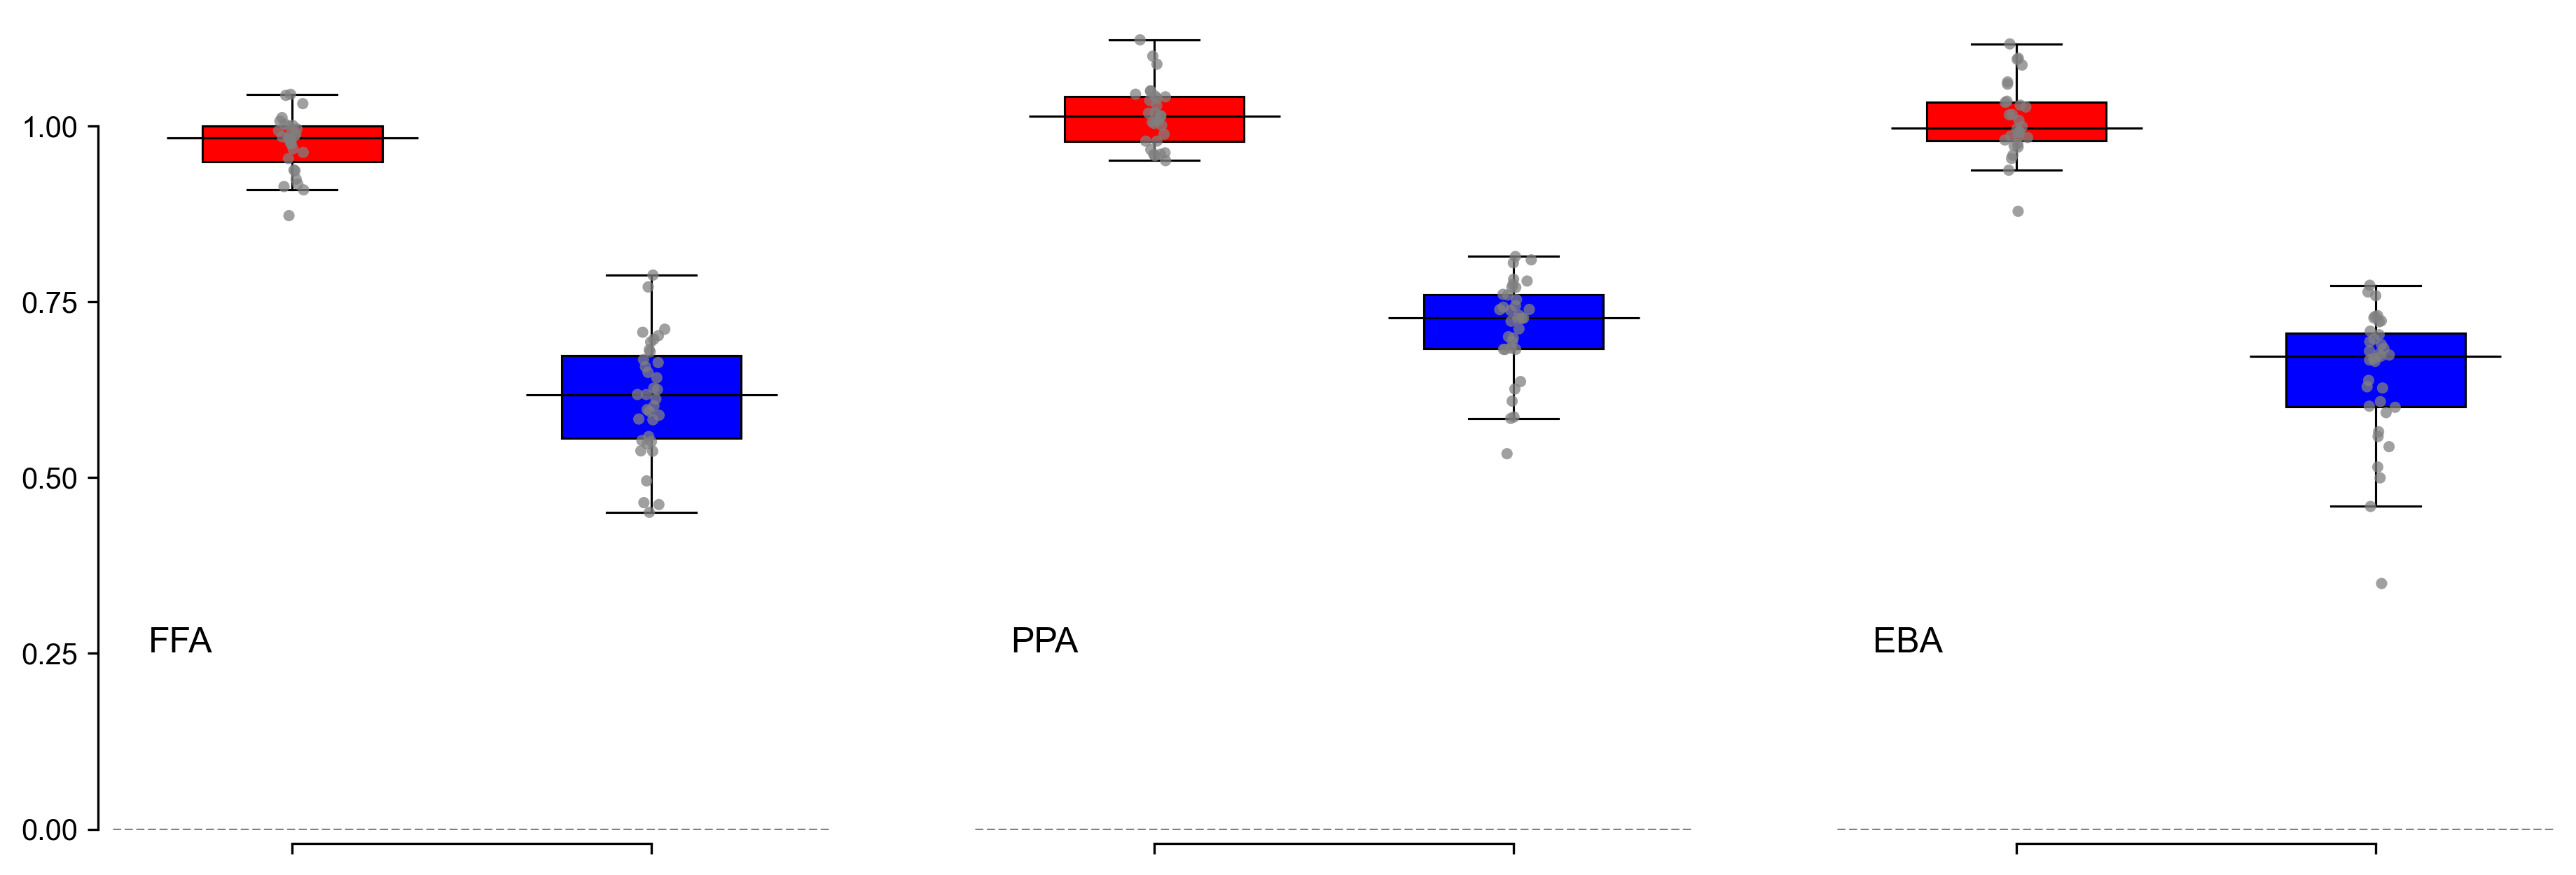


normed_rdmr
FFA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 23.32, p-value: 7.28e-32
PPA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 23.95, p-value: 6.78e-29
EBA
Number of Subject-Subject correlations: 28
Number of Model-Subject correlations: 35
t-value: 28.25, p-value: 9.86e-37


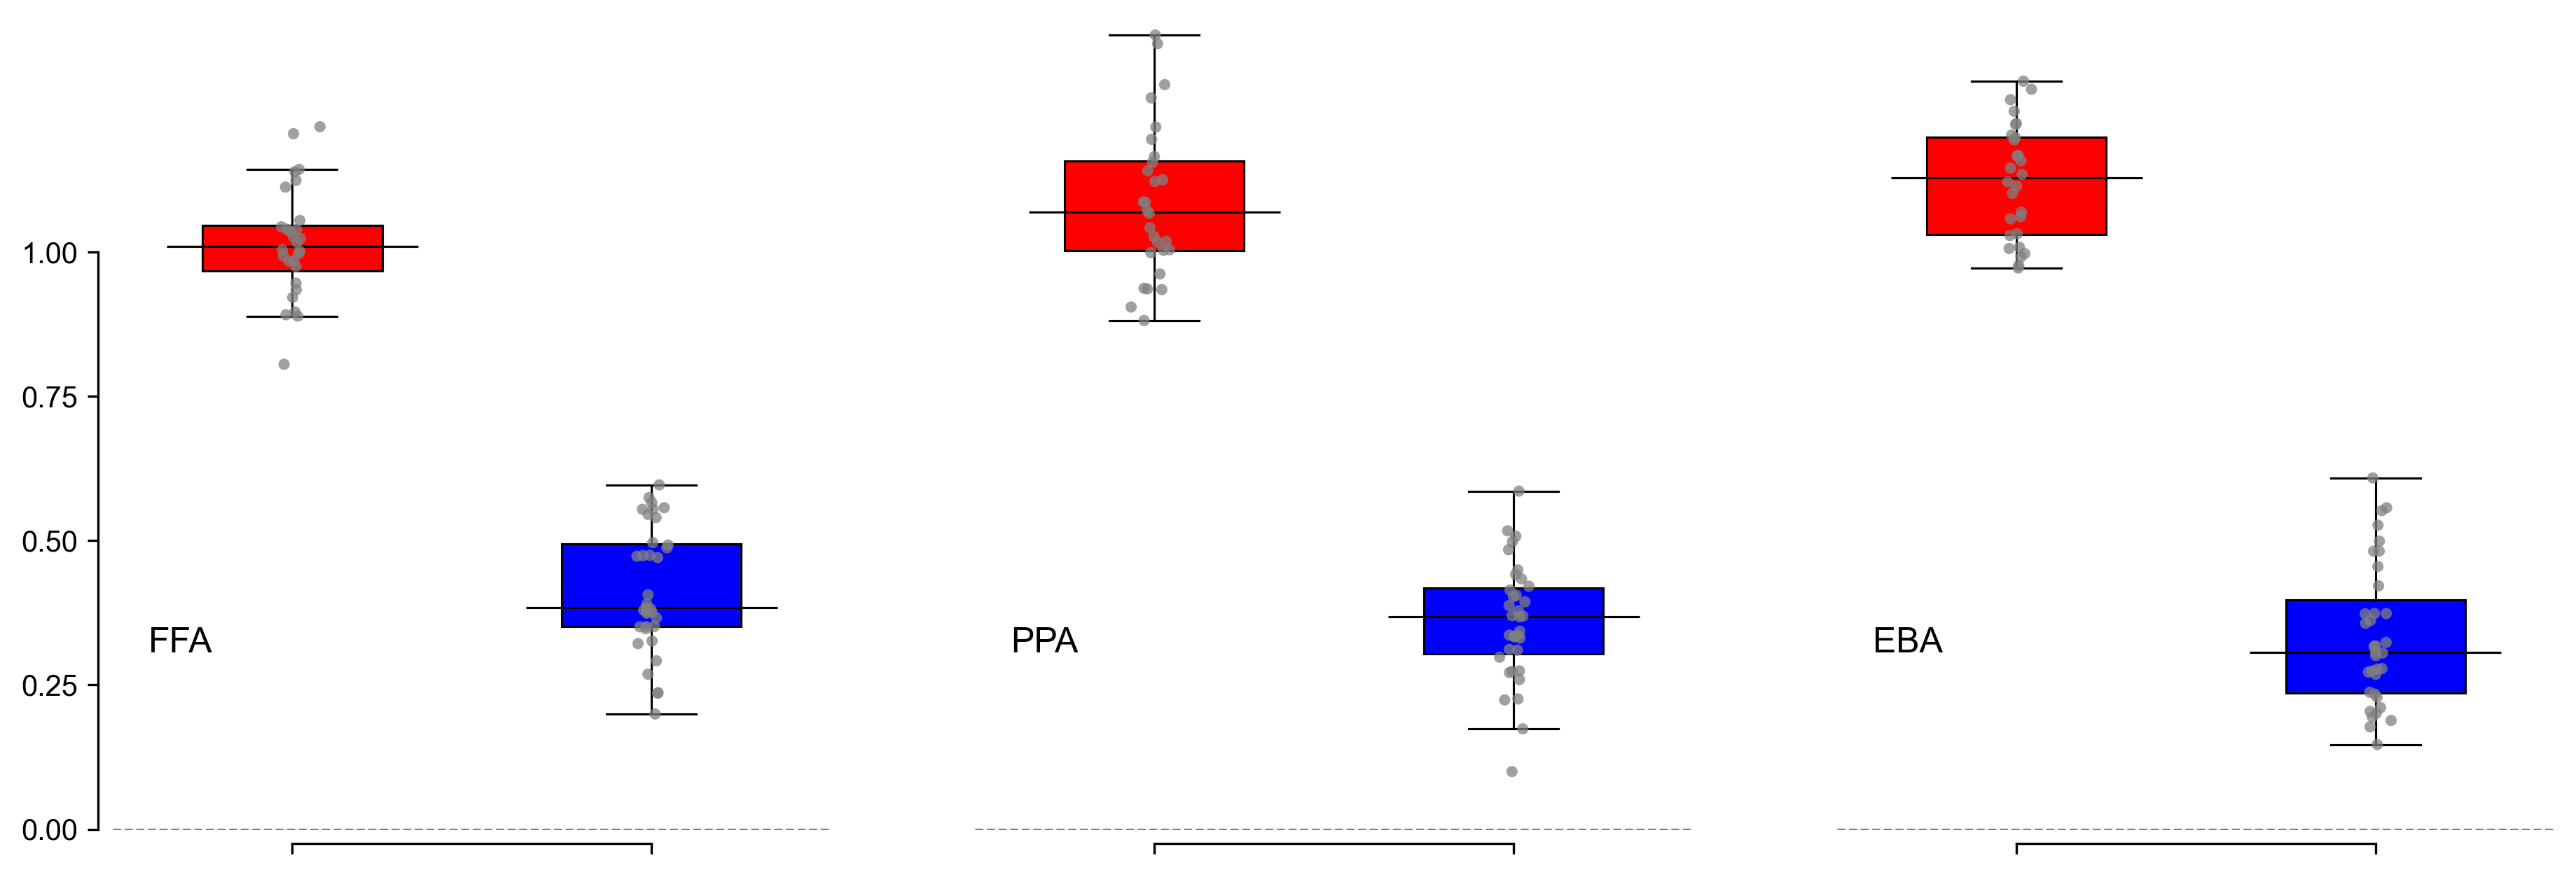

In [3]:
savefig = False

plot_dir = f'{PLOTS_DIR}/section2_3/individual_plots'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = taskoptimized_model_names

hh_color = 'red'
mh_color = 'blue'
colors = [hh_color, mh_color]

metrics = ['normed_pearsonr', 'normed_rdmr']
metric_ylims = {
    'normed_pearsonr': (0, 1.15),
    'normed_rdmr': (0, 1.4),
}

for metric in metrics:
    print('\n' + metric)
    # fig, ax = plt.figure(figsize=(5, 5), dpi=300)
    fig, axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5), dpi=300)

    for fidx, froi in enumerate(frois):
        print(froi)
        hh_medians = []
        for subject in subjects:
            subjectsubject_froi = subjectsubject_correlations_csv[
                (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                (subjectsubject_correlations_csv['subject1'] == subject) &
                (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
            ]
            hh_medians += list(subjectsubject_froi[metric])
        hh_medians = np.array(hh_medians).flatten()

        mh_medians, mh_sems = [], []
        for model in models:
            modelsubject_froi = modelsubject_correlations_csv[
                (modelsubject_correlations_csv['fmri_froi'] == froi) &
                (modelsubject_correlations_csv['model_name'] == model) &
                (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
                (modelsubject_correlations_csv['model_localizer'] == model_localizer)
            ]
            mh_medians.append(modelsubject_froi[metric].median())
            mh_sems.append(modelsubject_froi[metric].sem())
        mh_medians = np.array(mh_medians)
        mh_sems = np.array(mh_sems)

        jitter_scale = 0.01 #0.05
        scatter_pad = 0 # 0.05
        alpha = 0.75 # 0.5
        markersize = 15 # 25

        bar_positions = np.array([0, 0.5])

        # y=0 line
        axs[fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

        # Box plot
        box_data = [hh_medians, mh_medians]
        linewidth = 0.75
        barwidth = 0.25 # 0.35
        boxes = axs[fidx].boxplot(
                    box_data, positions=bar_positions, patch_artist=True, 
                    widths=barwidth, showfliers=False,
                    boxprops={'color': 'black', 'linewidth': linewidth},
                    whiskerprops=dict(linewidth=linewidth),
                    capprops=dict(linewidth=linewidth),
                    medianprops={'color': 'black', 'linewidth': linewidth},
                    flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
                )
        for i, data in enumerate(box_data):
            med = np.median(data)
            # Manually draw a longer median line
            x = bar_positions[i]  # X-position of the boxplot
            # 0.225
            axs[fidx].plot([x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
        
        # Color the boxes according to category colors
        for box, color in zip(boxes['boxes'], colors):
            box.set(facecolor=color)

        x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
        x_modelsubject = np.ones(len(mh_medians))*bar_positions[1] + np.random.normal(0, jitter_scale, len(mh_medians))
        x_subjectsubject += scatter_pad
        x_modelsubject += scatter_pad
        axs[fidx].scatter(
            x_subjectsubject, hh_medians, color='gray', alpha=alpha, label='Subject-Subject', zorder=5,
            edgecolors='none', s=markersize
        )
        axs[fidx].scatter(
            x_modelsubject, mh_medians, color='gray', alpha=alpha, label='Model-Subject', zorder=5,
            edgecolors='none', s=markersize
        )
        print(f'Number of Subject-Subject correlations: {len(hh_medians)}')
        print(f'Number of Model-Subject correlations: {len(mh_medians)}')
        
        # Conduct Welch's t-test
        t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
        axs[fidx].set_xticks(bar_positions)
        print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')
        
        # Write froi name in bottom left corner
        axs[fidx].text(0.05, 0.25, froi, transform=axs[fidx].transAxes, fontsize=12, verticalalignment='top')

        axs[fidx].spines['top'].set_visible(False)
        axs[fidx].spines['right'].set_visible(False)
        axs[fidx].spines['left'].set_position(('outward', 5))
        axs[fidx].spines['bottom'].set_position(('outward', 5))
        axs[fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[fidx].spines['left'].set_bounds(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        axs[fidx].set_ylim(metric_ylims[metric])
        axs[fidx].spines['bottom'].set_bounds(bar_positions[0], bar_positions[1])
        axs[fidx].set_xlim(bar_positions[0]-0.25, bar_positions[1]+0.25)
        axs[fidx].tick_params(axis='x', labelbottom=False)

        if froi != 'FFA':
            axs[fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[fidx].yaxis.set_ticks([])

    if savefig:
        plt.savefig(f'{plot_dir}/fig3_boxplot_{metric}.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    # plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()

# Supplementary figures

In [10]:
# Make folders for saving results
results_dir = f'{PLOTS_DIR}/section2_3/supplementary_figures/rdms_data'
assert os.path.exists(results_dir), f"Results directory {results_dir} does not exist. Please run the analysis scripts to generate the results before plotting."
plots_dir = f'{PLOTS_DIR}/section2_3/supplementary_figures'
os.makedirs(plots_dir, exist_ok=True)

tthreshold = 7

normed_rsa_pearsonr = torch.load(f'{results_dir}/ordered_normed_pearsonr_rsa_t{tthreshold}.pt')
normed_rsa_rdmr = torch.load(f'{results_dir}/ordered_normed_rdmr_rsa_t{tthreshold}.pt')

In [11]:
system_order = {
    ('subjects', 'FFA'): 'FFA',
    ('subjects', 'OFA'): 'OFA',
    ('models', ('FFA', 'FFA')): 'ANN face-selective',
    ('subjects', 'EBA'): 'EBA',
    ('subjects', 'FBA'): 'FBA',
    ('models', ('EBA', 'EBA')): 'ANN body-selective',
    ('subjects', 'PPA'): 'PPA',
    ('subjects', 'OPA'): 'OPA',
    ('models', ('PPA', 'PPA')): 'ANN scene-selective',
}
subjects = [1, 2, 3, 4, 5, 6, 7, 8]
model_names = ma.get_model_names('task_optimized')

# Gather ordered responses in a single dictionary
ordered_keys = []
for (system, froi_info), _ in system_order.items():
    if system == 'subjects':
        froi = froi_info
        for subject_number in subjects:
            ordered_keys.append(f'subject_{subject_number}_{froi}_t{tthreshold}')
    elif system == 'models':
        model_froi = froi_info[0]
        fmri_froi = froi_info[1]
        for model_name in model_names:
            ordered_keys.append(f'model_{model_name}_{model_froi}to{fmri_froi}_t{tthreshold}')

## S3: Noise-corrected univariate RDM

In [12]:
savefig = True
rsa_used = normed_rsa_pearsonr
figname = f'figS3_normed_pearsonr_rsa_t{tthreshold}.pdf'
vmin = -0.8
cbar_ticks = [-0.8, -0.4, 0, 0.4, 0.8, 1.0]
cbar_label = r"Noise-corrected univariate correlation, $R$"

# Plot raw rdmr rsa as heatmap
plt.figure(figsize=(10, 10), dpi=300)
vmax = 1.0  # Clamp max at 1
clamped_rsa = torch.clamp(rsa_used, min=vmin, max=vmax)
ax = sns.heatmap(clamped_rsa.cpu().numpy(), cmap='RdBu_r', vmin=vmin, vmax=vmax, center=0, square=True, cbar_kws={'extend': 'max', 'shrink': 0.8})
cbar = ax.collections[0].colorbar
cbar.set_ticks(cbar_ticks)
cbar.ax.tick_params(labelsize=8)
cbar.set_label(cbar_label, fontsize=10)
# Add lines to separate systems (after froi change or system type change)
system_boundaries = []
system_labels = []
current_system_type = None
current_froi = None
for idx, system_name in enumerate(ordered_keys):
    if system_name.startswith('subject_'):
        system_type = 'subjects'
        froi = system_name.split('_')[-2]  # Remove 'tthreshold'
    elif system_name.startswith('model_'):
        system_type = 'models'
        froi = system_name.split('_')[-2].split('to')[0]  # Remove 'to' and fmri_froi
    if current_system_type is None:
        current_system_type = system_type
        current_froi = froi
        # system_label = system_order[(current_system_type, current_froi)]
        # system_labels.append(system_label)
    else:
        if system_type != current_system_type or froi != current_froi:
            system_boundaries.append(idx)
            current_froi_ = froi if current_system_type == 'subjects' else (froi, froi)
            # system_label = system_order[(current_system_type, current_froi_)]
            # print(current_system_type, current_froi_, 'label= ',system_label)
            # system_labels.append(system_label)
            current_system_type = system_type
            current_froi = froi
# Add the last section label
# current_froi_ = froi if current_system_type == 'subjects' else (froi, froi)
# system_labels.append(system_order[(current_system_type, current_froi_)])
system_labels = list(system_order.values())

for sbidx, boundary in enumerate(system_boundaries):
    if (sbidx+1)%3 == 0:
        plt.axhline(boundary, color='black', linestyle='-', linewidth=1.5)
        plt.axvline(boundary, color='black', linestyle='-', linewidth=1.5)
    else:
        plt.axhline(boundary, color='black', linestyle='--', linewidth=0.75)
        plt.axvline(boundary, color='black', linestyle='--', linewidth=0.75)
# Add system labels
midpoints = []
start_idx = 0
for boundary in system_boundaries + [len(ordered_keys)]:
    midpoint = (start_idx + boundary) / 2
    midpoints.append(midpoint)
    start_idx = boundary
plt.xticks(midpoints, system_labels, rotation=0)
plt.yticks(midpoints, system_labels, rotation=90)
plt.tick_params(axis='both', length=0, labelsize=8)
# Place x-axis labels on top
plt.gca().xaxis.set_ticks_position('top')
plt.gca().xaxis.set_label_position('top')
# plt.title('Normed RDMR RSA Heatmap')
# plt.xlabel('Systems')
# plt.ylabel('Systems')
plt.tight_layout(pad=0.2)
if savefig:
    plt.savefig(f'{plots_dir}/{figname}', dpi=300, transparent=True) # , bbox_inches='tight'
else:
    plt.show()
plt.close()

## S4: Noise-corrected multivariate RDM

In [13]:
savefig = True
rsa_used = normed_rsa_rdmr
figname = f'figS4_normed_rdmr_rsa_t{tthreshold}.pdf'
vmin = -0.4
cbar_ticks = [-0.4, 0, 0.4, 0.8, 1.0]
cbar_label = r"Noise-corrected multivariate correlation, $R$"

# Plot raw rdmr rsa as heatmap
plt.figure(figsize=(10, 10), dpi=300)
vmax = 1.0  # Clamp max at 1
clamped_rsa = torch.clamp(rsa_used, min=vmin, max=vmax)
ax = sns.heatmap(clamped_rsa.cpu().numpy(), cmap='RdBu_r', vmin=vmin, vmax=vmax, center=0, square=True, cbar_kws={'extend': 'max', 'shrink': 0.8})
cbar = ax.collections[0].colorbar
cbar.set_ticks(cbar_ticks)
cbar.ax.tick_params(labelsize=8)
cbar.set_label(cbar_label, fontsize=10)
# Add lines to separate systems (after froi change or system type change)
system_boundaries = []
system_labels = []
current_system_type = None
current_froi = None
for idx, system_name in enumerate(ordered_keys):
    if system_name.startswith('subject_'):
        system_type = 'subjects'
        froi = system_name.split('_')[-2]  # Remove 'tthreshold'
    elif system_name.startswith('model_'):
        system_type = 'models'
        froi = system_name.split('_')[-2].split('to')[0]  # Remove 'to' and fmri_froi
    if current_system_type is None:
        current_system_type = system_type
        current_froi = froi
        # system_label = system_order[(current_system_type, current_froi)]
        # system_labels.append(system_label)
    else:
        if system_type != current_system_type or froi != current_froi:
            system_boundaries.append(idx)
            current_froi_ = froi if current_system_type == 'subjects' else (froi, froi)
            # system_label = system_order[(current_system_type, current_froi_)]
            # print(current_system_type, current_froi_, 'label= ',system_label)
            # system_labels.append(system_label)
            current_system_type = system_type
            current_froi = froi
# Add the last section label
# current_froi_ = froi if current_system_type == 'subjects' else (froi, froi)
# system_labels.append(system_order[(current_system_type, current_froi_)])
system_labels = list(system_order.values())

for sbidx, boundary in enumerate(system_boundaries):
    if (sbidx+1)%3 == 0:
        plt.axhline(boundary, color='black', linestyle='-', linewidth=1.5)
        plt.axvline(boundary, color='black', linestyle='-', linewidth=1.5)
    else:
        plt.axhline(boundary, color='black', linestyle='--', linewidth=0.75)
        plt.axvline(boundary, color='black', linestyle='--', linewidth=0.75)
# Add system labels
midpoints = []
start_idx = 0
for boundary in system_boundaries + [len(ordered_keys)]:
    midpoint = (start_idx + boundary) / 2
    midpoints.append(midpoint)
    start_idx = boundary
plt.xticks(midpoints, system_labels, rotation=0)
plt.yticks(midpoints, system_labels, rotation=90)
plt.tick_params(axis='both', length=0, labelsize=8)
# Place x-axis labels on top
plt.gca().xaxis.set_ticks_position('top')
plt.gca().xaxis.set_label_position('top')
# plt.title('Normed RDMR RSA Heatmap')
# plt.xlabel('Systems')
# plt.ylabel('Systems')
plt.tight_layout(pad=0.2)
if savefig:
    plt.savefig(f'{plots_dir}/{figname}', dpi=300, transparent=True) # , bbox_inches='tight'
else:
    plt.show()
plt.close()

## Possible main figure: Only FFA/EBA/PPA RDM

In [5]:
system_order = {
    ('subjects', 'FFA'): 'FFA',
    # ('subjects', 'OFA'): 'OFA',
    ('models', ('FFA', 'FFA')): 'ANN face-selective',
    ('subjects', 'EBA'): 'EBA',
    # ('subjects', 'FBA'): 'FBA',
    ('models', ('EBA', 'EBA')): 'ANN body-selective',
    ('subjects', 'PPA'): 'PPA',
    # ('subjects', 'OPA'): 'OPA',
    ('models', ('PPA', 'PPA')): 'ANN scene-selective',
}
subjects = [1, 2, 3, 4, 5, 6, 7, 8]
model_names = ma.get_model_names('task_optimized')

# Gather ordered responses in a single dictionary
ordered_keys = []
for (system, froi_info), _ in system_order.items():
    if system == 'subjects':
        froi = froi_info
        for subject_number in subjects:
            ordered_keys.append(f'subject_{subject_number}_{froi}_t{tthreshold}')
    elif system == 'models':
        model_froi = froi_info[0]
        fmri_froi = froi_info[1]
        for model_name in model_names:
            ordered_keys.append(f'model_{model_name}_{model_froi}to{fmri_froi}_t{tthreshold}')

### Univariate

Minimum and maximum values in the reduced RSA matrix: -0.734, 1.206


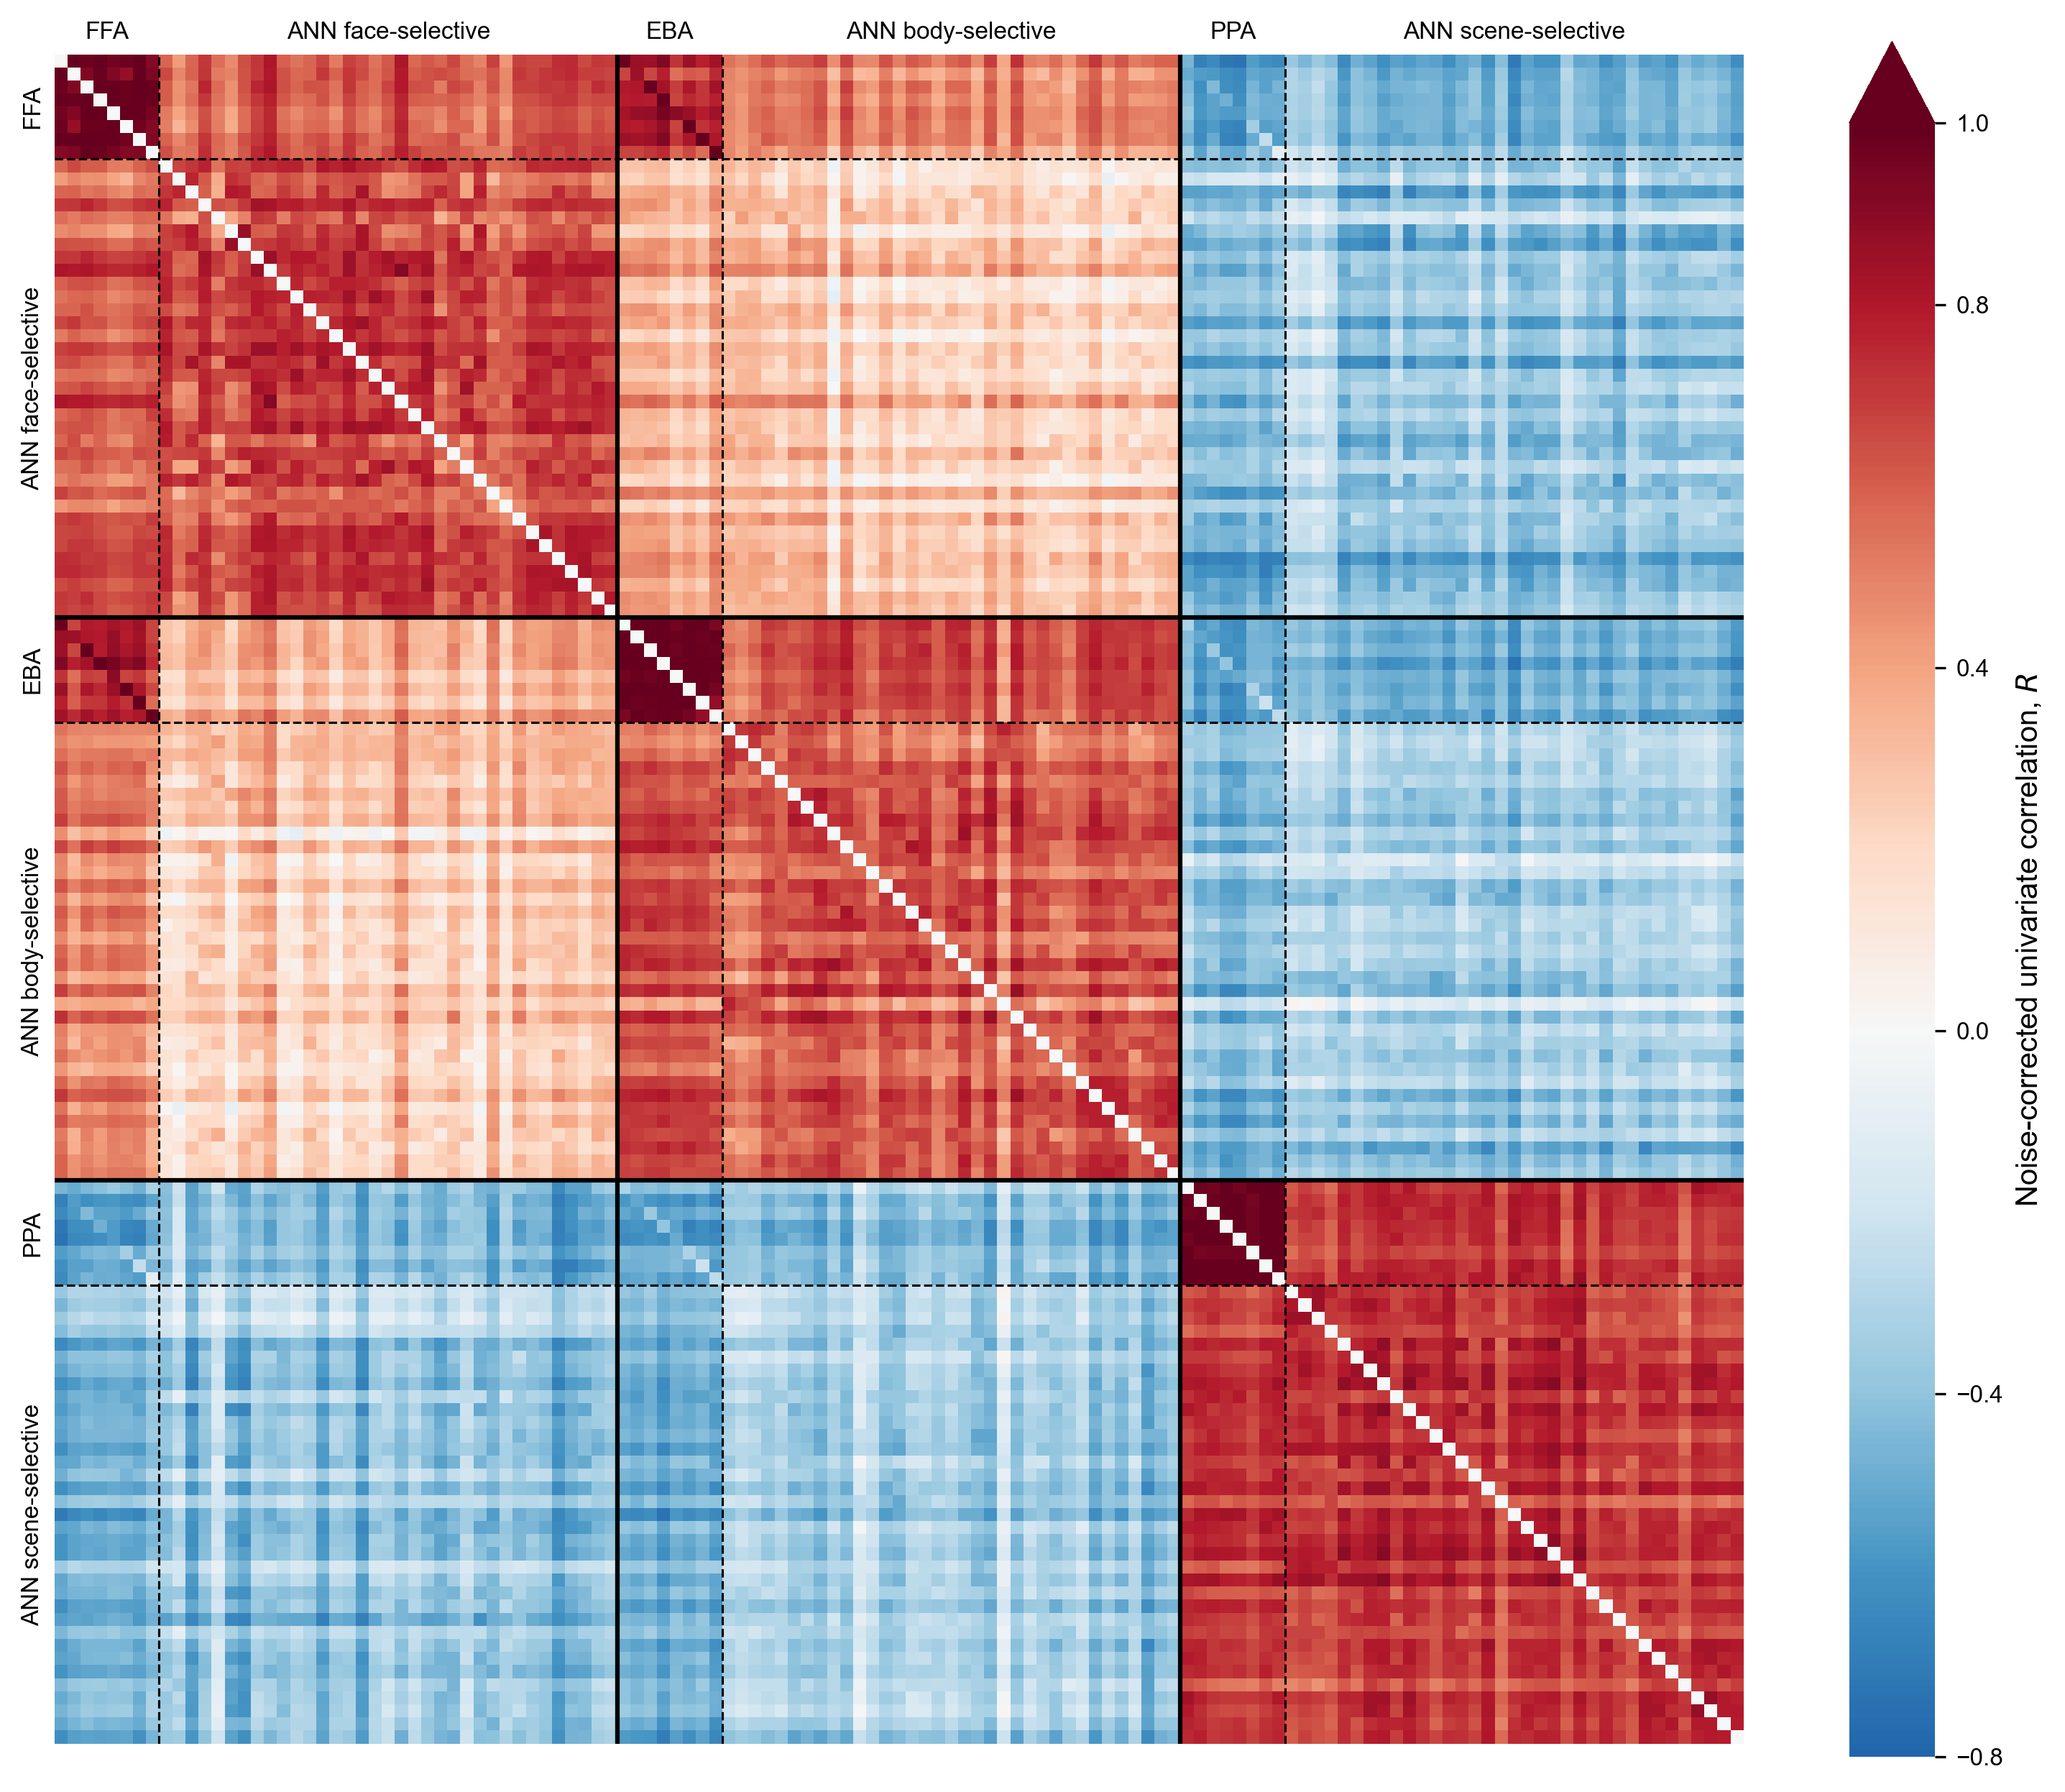

In [8]:
savefig = True
rsa_used = torch.clone(normed_rsa_pearsonr)
figname = 'fig3c_RDM_univariate.pdf'
plot_dir = f'{PLOTS_DIR}/section2_3/main_figure/individual_plots'

# Drop OFA (index 8-15), FBA (59-66), OPA (110-117) from the heatmap to focus on the main comparisons
# Indices to drop
drop_ranges = [
    range(8, 16),      # OFA
    range(59, 67),     # FBA
    range(110, 118)    # OPA
]
# Flatten drop indices
drop_idx = sorted([i for r in drop_ranges for i in r])
# Create mask of indices to keep
all_idx = torch.arange(rsa_used.shape[0])
keep_mask = ~torch.isin(all_idx, torch.tensor(drop_idx))
# Apply mask to rows and columns
rsa_reduced = rsa_used[keep_mask][:, keep_mask]
rsa_used = rsa_reduced
print(f'Minimum and maximum values in the reduced RSA matrix: {rsa_used.min().item():.3f}, {rsa_used.max().item():.3f}')

vmin = -0.8
cbar_ticks = [-0.8, -0.4, 0, 0.4, 0.8, 1.0]
cbar_label = r"Noise-corrected univariate correlation, $R$"

# Plot raw rdmr rsa as heatmap
plt.figure(figsize=(10, 10), dpi=300)
vmax = 1.0  # Clamp max at 1
clamped_rsa = torch.clamp(rsa_used, min=vmin, max=vmax)
ax = sns.heatmap(clamped_rsa.cpu().numpy(), cmap='RdBu_r', vmin=vmin, vmax=vmax, center=0, square=True, cbar_kws={'extend': 'max', 'shrink': 0.8})
cbar = ax.collections[0].colorbar
cbar.set_ticks(cbar_ticks)
cbar.ax.tick_params(labelsize=8)
cbar.set_label(cbar_label, fontsize=10)
# Add lines to separate systems (after froi change or system type change)
system_boundaries = []
system_labels = []
current_system_type = None
current_froi = None
for idx, system_name in enumerate(ordered_keys):
    if system_name.startswith('subject_'):
        system_type = 'subjects'
        froi = system_name.split('_')[-2]  # Remove 'tthreshold'
    elif system_name.startswith('model_'):
        system_type = 'models'
        froi = system_name.split('_')[-2].split('to')[0]  # Remove 'to' and fmri_froi
    if current_system_type is None:
        current_system_type = system_type
        current_froi = froi
        # system_label = system_order[(current_system_type, current_froi)]
        # system_labels.append(system_label)
    else:
        if system_type != current_system_type or froi != current_froi:
            system_boundaries.append(idx)
            current_froi_ = froi if current_system_type == 'subjects' else (froi, froi)
            # system_label = system_order[(current_system_type, current_froi_)]
            # print(current_system_type, current_froi_, 'label= ',system_label)
            # system_labels.append(system_label)
            current_system_type = system_type
            current_froi = froi
# Add the last section label
# current_froi_ = froi if current_system_type == 'subjects' else (froi, froi)
# system_labels.append(system_order[(current_system_type, current_froi_)])
system_labels = list(system_order.values())

for sbidx, boundary in enumerate(system_boundaries):
    if (sbidx+1)%2 == 0:
        plt.axhline(boundary, color='black', linestyle='-', linewidth=1.5)
        plt.axvline(boundary, color='black', linestyle='-', linewidth=1.5)
    else:
        plt.axhline(boundary, color='black', linestyle='--', linewidth=0.75)
        plt.axvline(boundary, color='black', linestyle='--', linewidth=0.75)
# Add system labels
midpoints = []
start_idx = 0
for boundary in system_boundaries + [len(ordered_keys)]:
    midpoint = (start_idx + boundary) / 2
    midpoints.append(midpoint)
    start_idx = boundary
plt.xticks(midpoints, system_labels, rotation=0)
plt.yticks(midpoints, system_labels, rotation=90)
plt.tick_params(axis='both', length=0, labelsize=8)
# Place x-axis labels on top
plt.gca().xaxis.set_ticks_position('top')
plt.gca().xaxis.set_label_position('top')
# plt.title('Normed RDMR RSA Heatmap')
# plt.xlabel('Systems')
# plt.ylabel('Systems')
plt.tight_layout(pad=0.2)
if savefig:
    plt.savefig(f'{plot_dir}/{figname}', dpi=300, transparent=True) # , bbox_inches='tight'
plt.show()
plt.close()

### Multivariate

Minimum and maximum values in the reduced RSA matrix: -0.334, 2.018


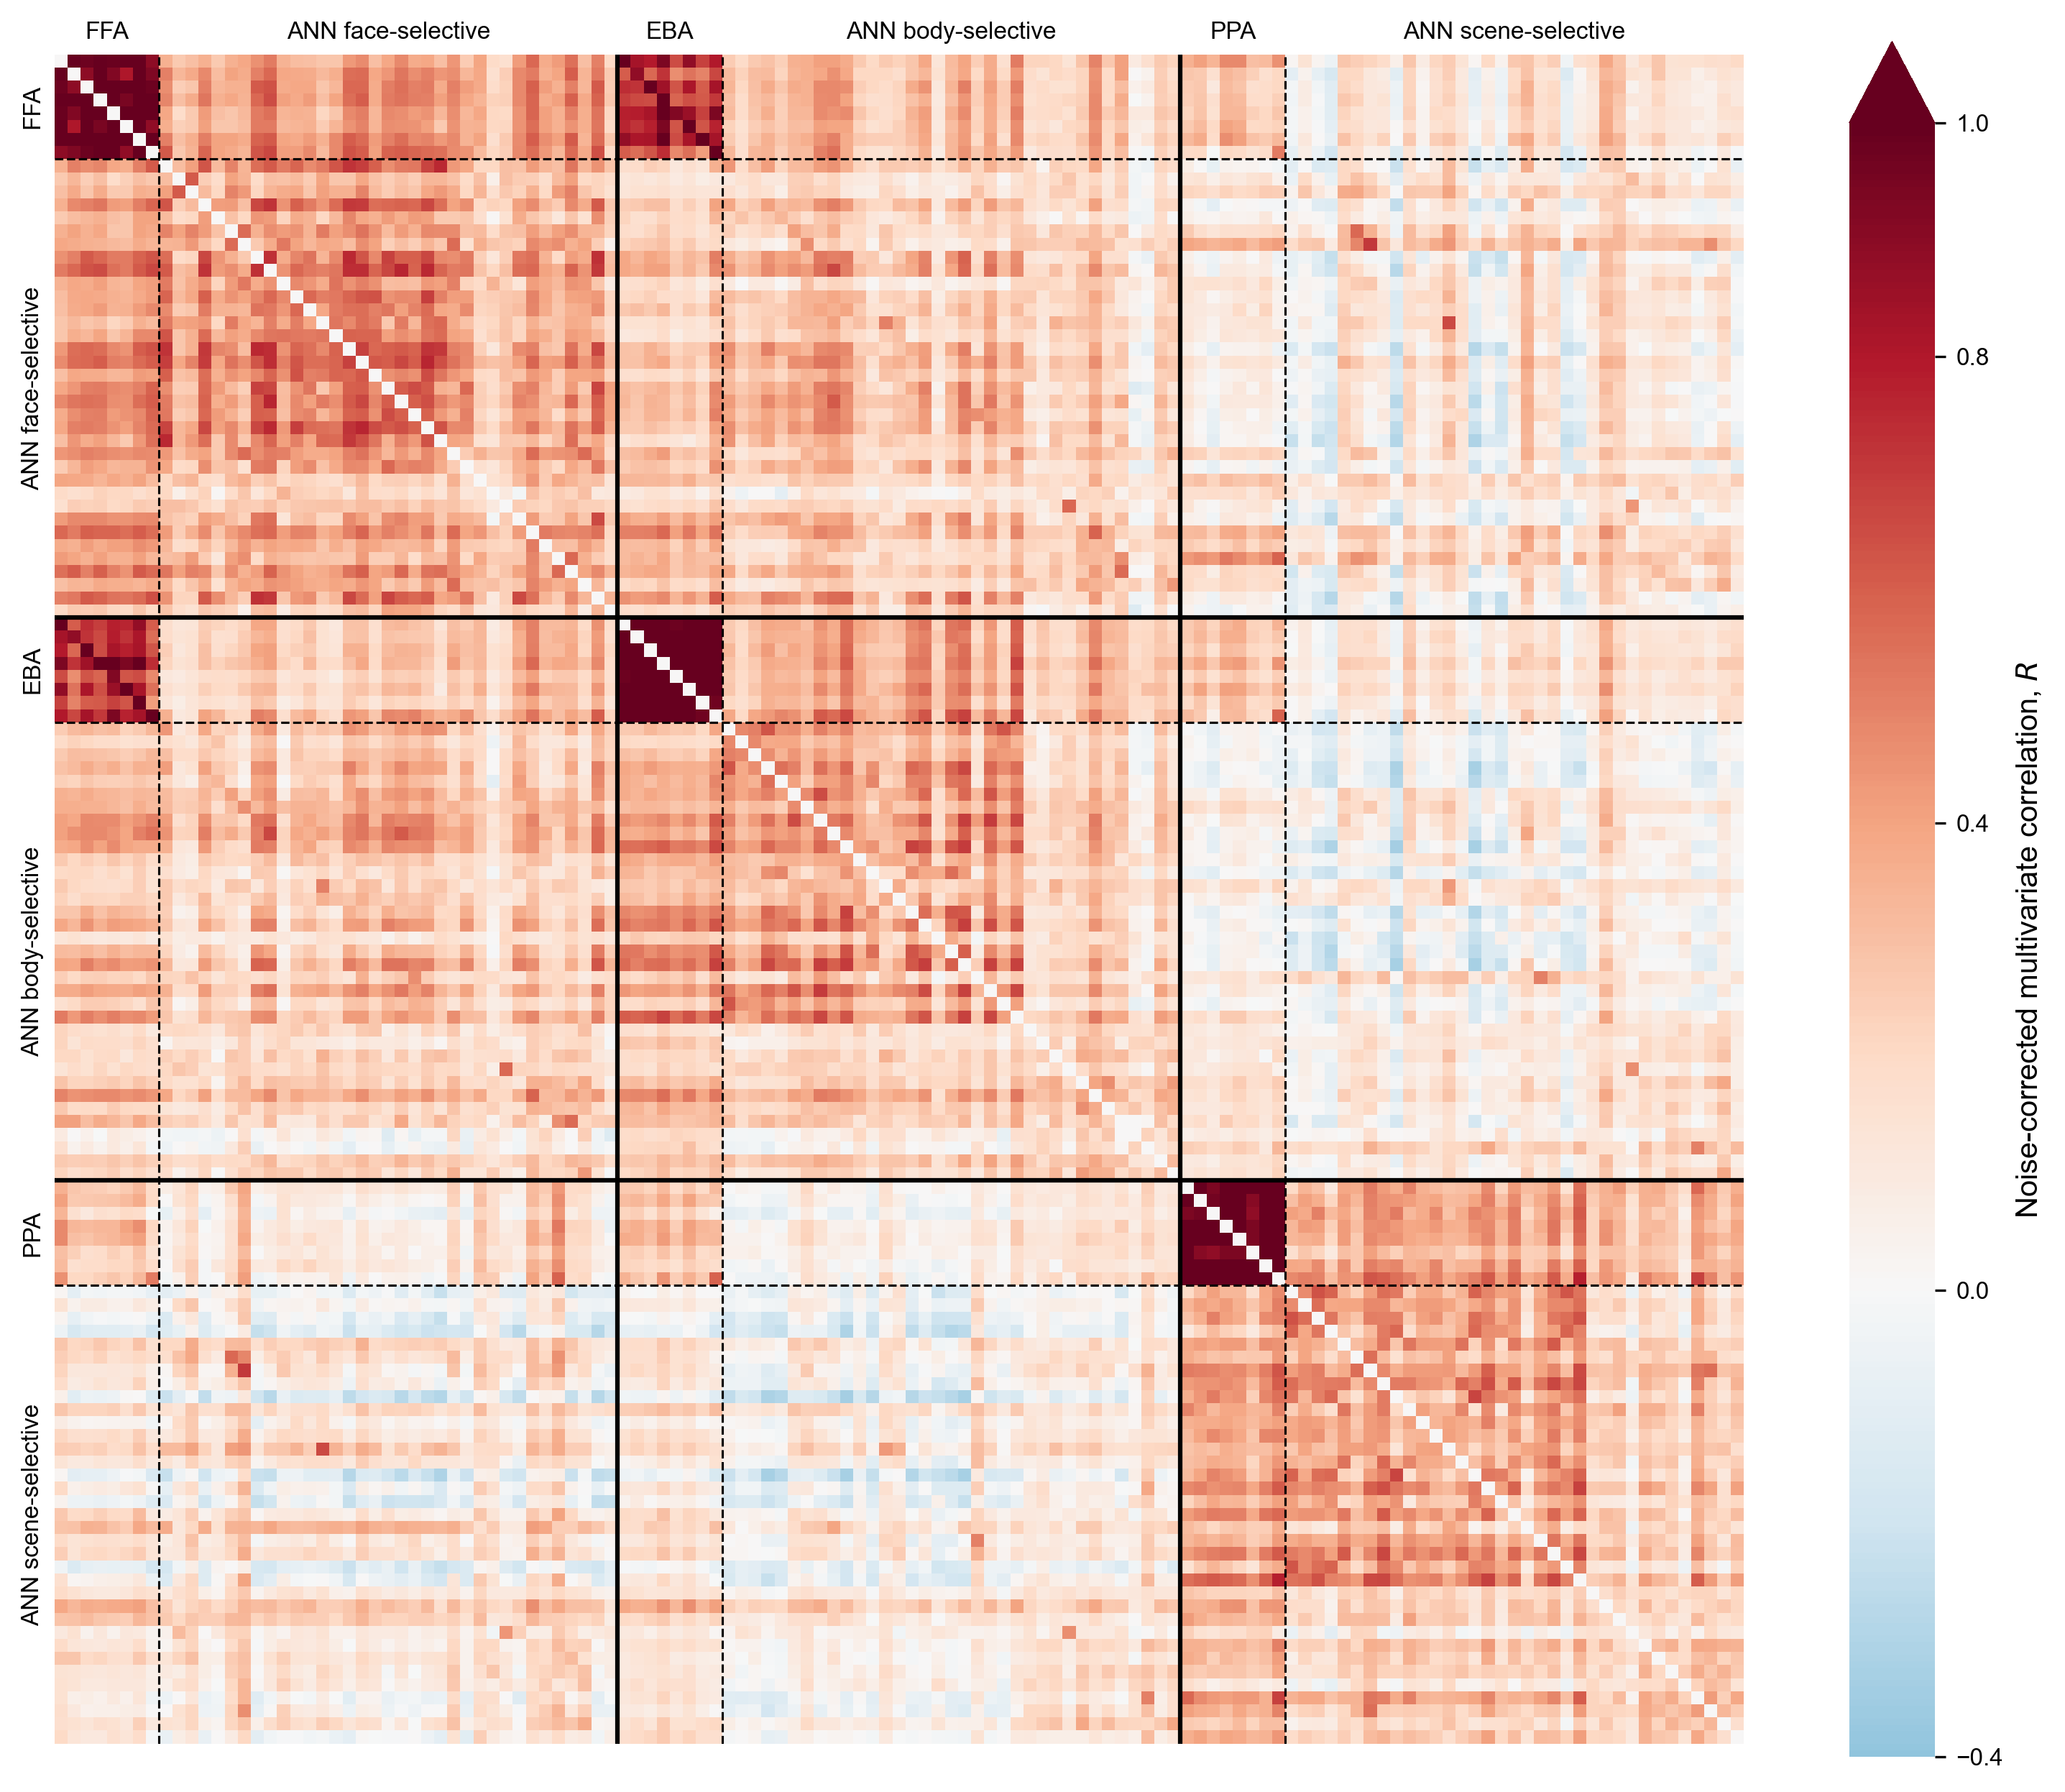

In [9]:
savefig = True
rsa_used = torch.clone(normed_rsa_rdmr)
figname = 'fig3c_RDM_multivariate.pdf'
plot_dir = f'{PLOTS_DIR}/section2_3/main_figure/individual_plots'

# Drop OFA (index 8-15), FBA (59-66), OPA (110-117) from the heatmap to focus on the main comparisons
# Indices to drop
drop_ranges = [
    range(8, 16),      # OFA
    range(59, 67),     # FBA
    range(110, 118)    # OPA
]
# Flatten drop indices
drop_idx = sorted([i for r in drop_ranges for i in r])
# Create mask of indices to keep
all_idx = torch.arange(rsa_used.shape[0])
keep_mask = ~torch.isin(all_idx, torch.tensor(drop_idx))
# Apply mask to rows and columns
rsa_reduced = rsa_used[keep_mask][:, keep_mask]
rsa_used = rsa_reduced
print(f'Minimum and maximum values in the reduced RSA matrix: {rsa_used.min().item():.3f}, {rsa_used.max().item():.3f}')

vmin = -0.4
cbar_ticks = [-0.4, 0, 0.4, 0.8, 1.0]
cbar_label = r"Noise-corrected multivariate correlation, $R$"

# Plot raw rdmr rsa as heatmap
plt.figure(figsize=(10, 10), dpi=300)
vmax = 1.0  # Clamp max at 1
clamped_rsa = torch.clamp(rsa_used, min=vmin, max=vmax)
ax = sns.heatmap(clamped_rsa.cpu().numpy(), cmap='RdBu_r', vmin=vmin, vmax=vmax, center=0, square=True, cbar_kws={'extend': 'max', 'shrink': 0.8})
cbar = ax.collections[0].colorbar
cbar.set_ticks(cbar_ticks)
cbar.ax.tick_params(labelsize=8)
cbar.set_label(cbar_label, fontsize=10)
# Add lines to separate systems (after froi change or system type change)
system_boundaries = []
system_labels = []
current_system_type = None
current_froi = None
for idx, system_name in enumerate(ordered_keys):
    if system_name.startswith('subject_'):
        system_type = 'subjects'
        froi = system_name.split('_')[-2]  # Remove 'tthreshold'
    elif system_name.startswith('model_'):
        system_type = 'models'
        froi = system_name.split('_')[-2].split('to')[0]  # Remove 'to' and fmri_froi
    if current_system_type is None:
        current_system_type = system_type
        current_froi = froi
        # system_label = system_order[(current_system_type, current_froi)]
        # system_labels.append(system_label)
    else:
        if system_type != current_system_type or froi != current_froi:
            system_boundaries.append(idx)
            current_froi_ = froi if current_system_type == 'subjects' else (froi, froi)
            # system_label = system_order[(current_system_type, current_froi_)]
            # print(current_system_type, current_froi_, 'label= ',system_label)
            # system_labels.append(system_label)
            current_system_type = system_type
            current_froi = froi
# Add the last section label
# current_froi_ = froi if current_system_type == 'subjects' else (froi, froi)
# system_labels.append(system_order[(current_system_type, current_froi_)])
system_labels = list(system_order.values())

for sbidx, boundary in enumerate(system_boundaries):
    if (sbidx+1)%2 == 0:
        plt.axhline(boundary, color='black', linestyle='-', linewidth=1.5)
        plt.axvline(boundary, color='black', linestyle='-', linewidth=1.5)
    else:
        plt.axhline(boundary, color='black', linestyle='--', linewidth=0.75)
        plt.axvline(boundary, color='black', linestyle='--', linewidth=0.75)
# Add system labels
midpoints = []
start_idx = 0
for boundary in system_boundaries + [len(ordered_keys)]:
    midpoint = (start_idx + boundary) / 2
    midpoints.append(midpoint)
    start_idx = boundary
plt.xticks(midpoints, system_labels, rotation=0)
plt.yticks(midpoints, system_labels, rotation=90)
plt.tick_params(axis='both', length=0, labelsize=8)
# Place x-axis labels on top
plt.gca().xaxis.set_ticks_position('top')
plt.gca().xaxis.set_label_position('top')
# plt.title('Normed RDMR RSA Heatmap')
# plt.xlabel('Systems')
# plt.ylabel('Systems')
plt.tight_layout(pad=0.2)
if savefig:
    plt.savefig(f'{plot_dir}/{figname}', dpi=300, transparent=True) # , bbox_inches='tight'
plt.show()
plt.close()

#### Model convergence based on architecture

In [117]:
system_order = {
    # ('subjects', 'FFA'): 'FFA',
    # ('subjects', 'OFA'): 'OFA',
    ('models', ('FFA', 'FFA')): 'ANN face-selective',
    # ('subjects', 'EBA'): 'EBA',
    # ('subjects', 'FBA'): 'FBA',
    ('models', ('EBA', 'EBA')): 'ANN body-selective',
    # ('subjects', 'PPA'): 'PPA',
    # ('subjects', 'OPA'): 'OPA',
    ('models', ('PPA', 'PPA')): 'ANN scene-selective',
}
subjects = [1, 2, 3, 4, 5, 6, 7, 8]
model_names = ma.get_model_names('task_optimized')

# Gather ordered responses in a single dictionary
ordered_keys = []
for (system, froi_info), _ in system_order.items():
    if system == 'subjects':
        froi = froi_info
        for subject_number in subjects:
            ordered_keys.append(f'subject_{subject_number}_{froi}_t{tthreshold}')
    elif system == 'models':
        model_froi = froi_info[0]
        fmri_froi = froi_info[1]
        for model_name in model_names:
            ordered_keys.append(f'model_{model_name}_{model_froi}to{fmri_froi}_t{tthreshold}')

Minimum and maximum values in the reduced RSA matrix: -0.691, 0.909


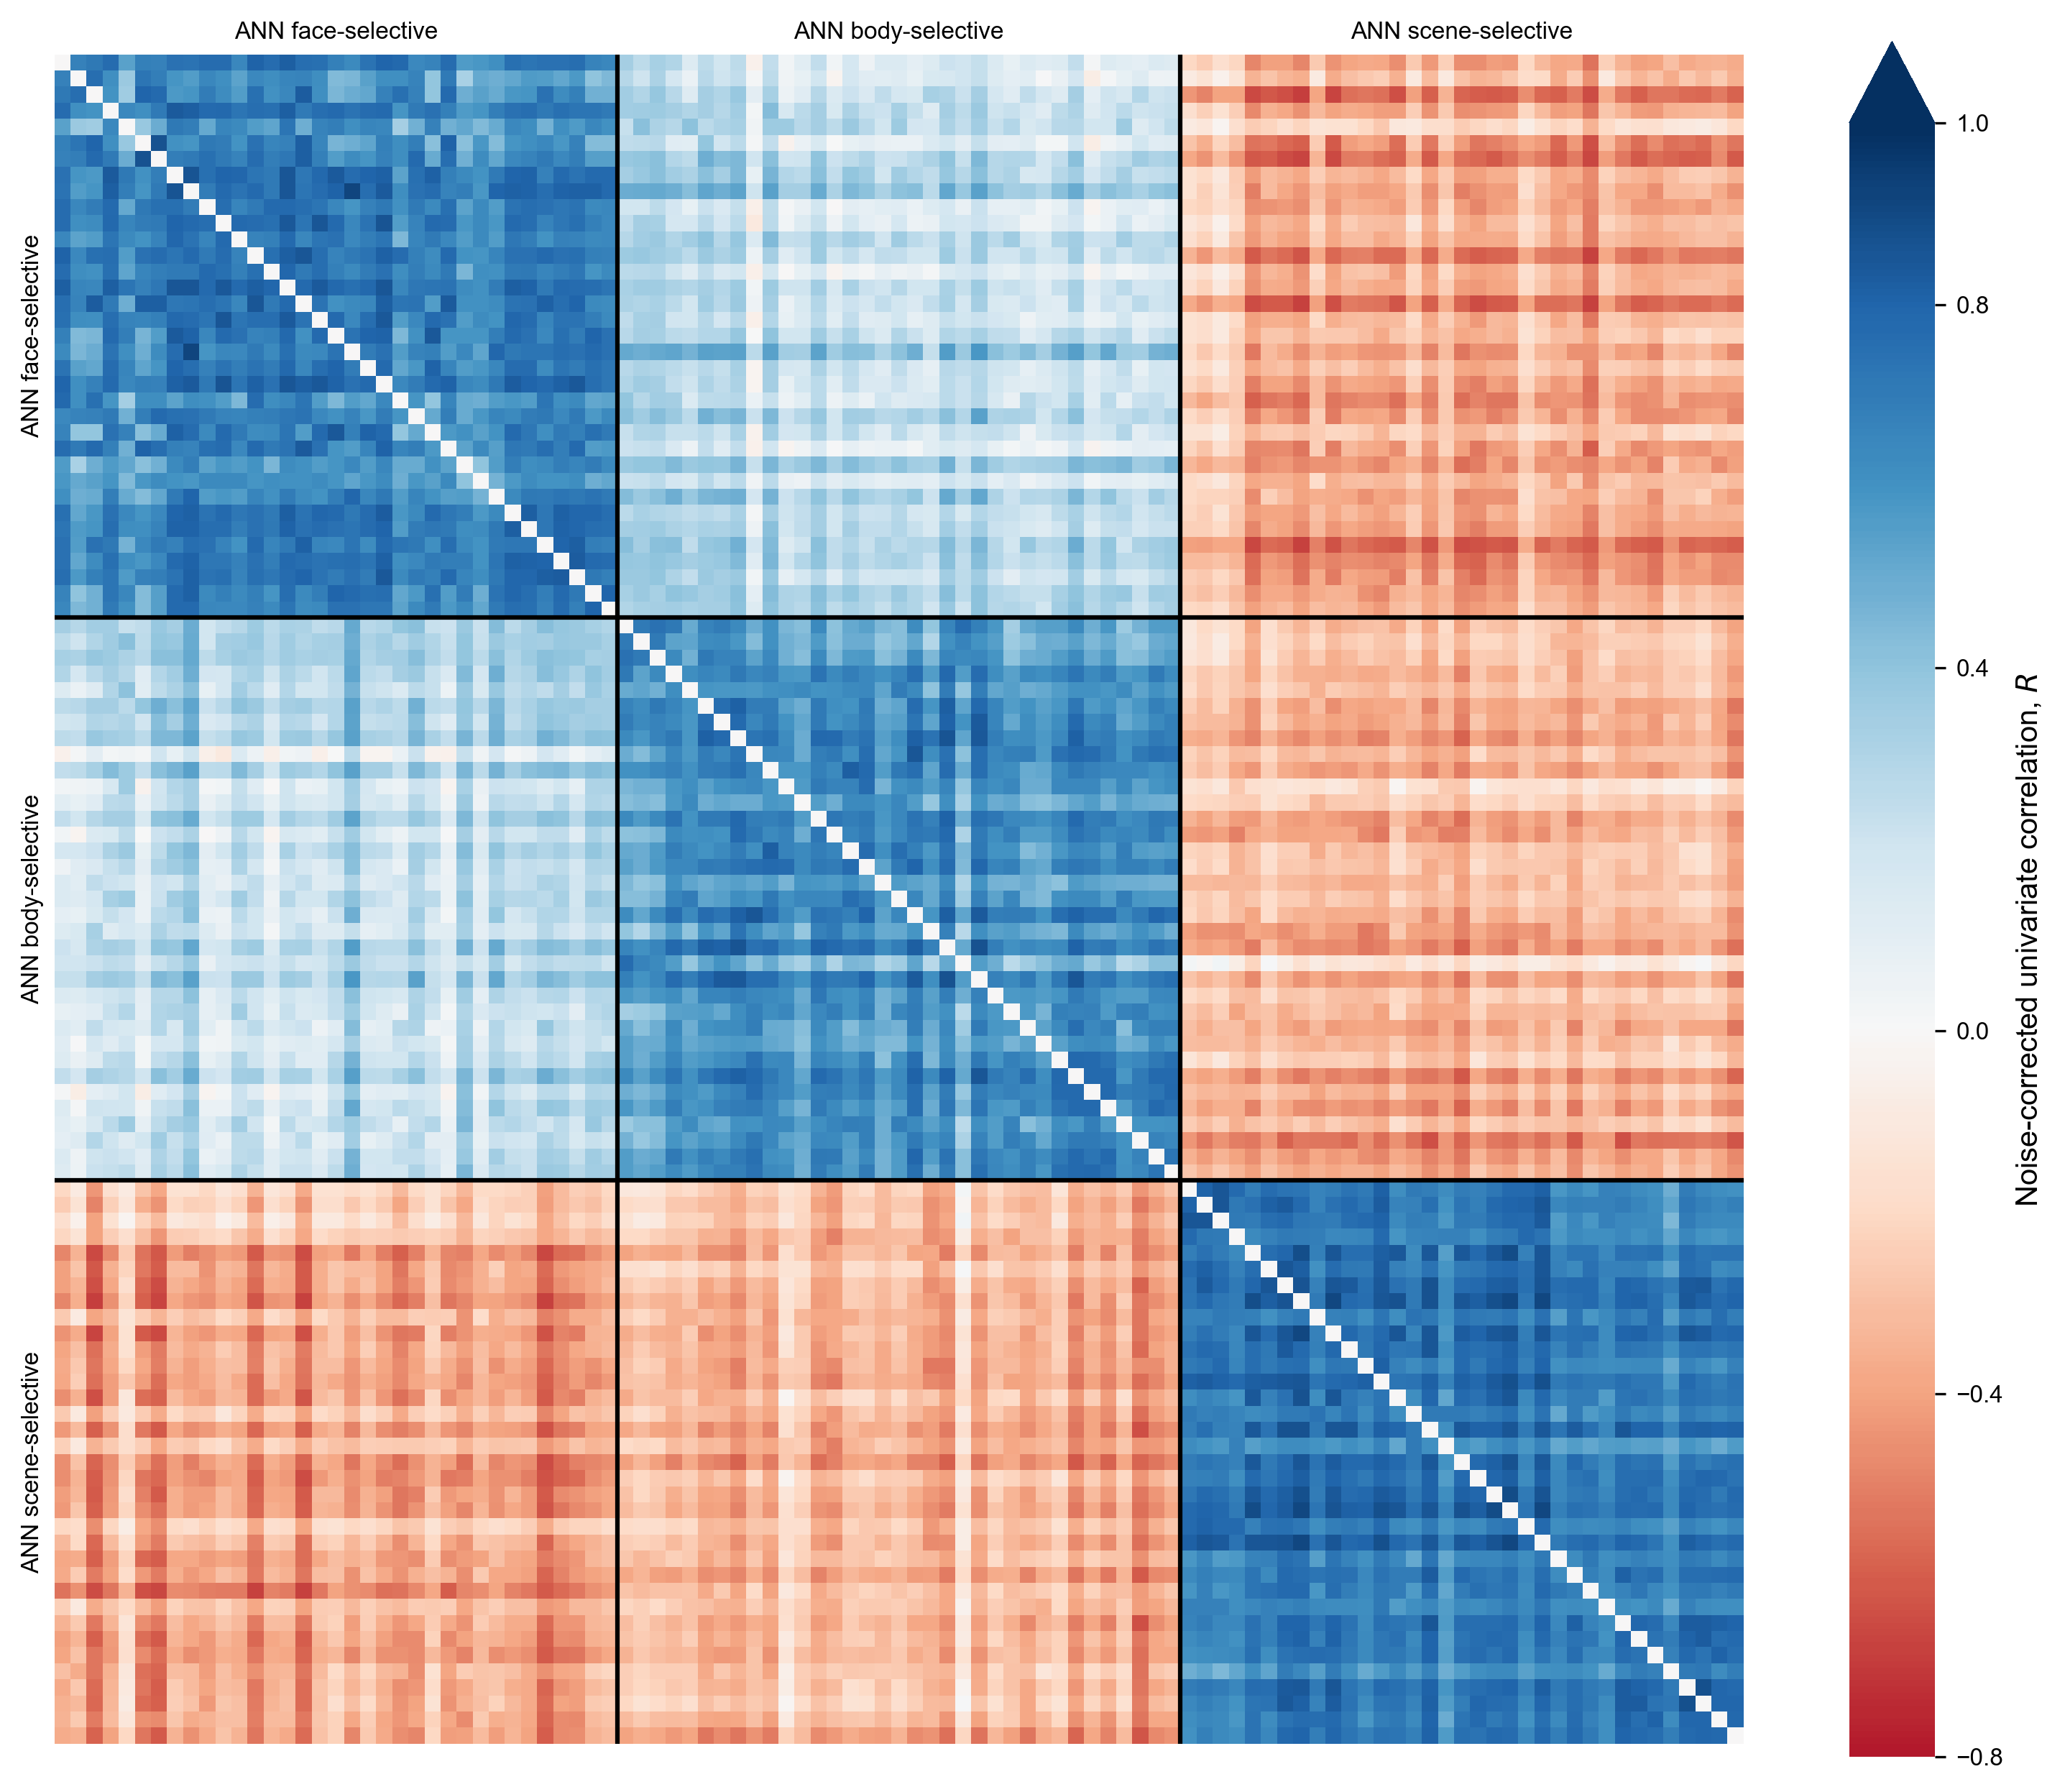

In [118]:
savefig = False
rsa_used = torch.clone(normed_rsa_pearsonr)
figname = None # f'figS3_normed_pearsonr_rsa_t{tthreshold}.pdf'

# Drop OFA (index 8-15), FBA (59-66), OPA (110-117) from the heatmap to focus on the main comparisons
# Indices to drop
drop_ranges = [
    range(0, 8),       # FFA
    range(8, 16),      # OFA
    range(51, 59),     # EBA
    range(59, 67),     # FBA
    range(102, 110),   # PPA
    range(110, 118)    # OPA
]
# Flatten drop indices
drop_idx = sorted([i for r in drop_ranges for i in r])
# Create mask of indices to keep
all_idx = torch.arange(rsa_used.shape[0])
keep_mask = ~torch.isin(all_idx, torch.tensor(drop_idx))
# Apply mask to rows and columns
rsa_reduced = rsa_used[keep_mask][:, keep_mask]
rsa_used = rsa_reduced
print(f'Minimum and maximum values in the reduced RSA matrix: {rsa_used.min().item():.3f}, {rsa_used.max().item():.3f}')

vmin = -0.8
cbar_ticks = [-0.8, -0.4, 0, 0.4, 0.8, 1.0]
cbar_label = r"Noise-corrected univariate correlation, $R$"

# Plot raw rdmr rsa as heatmap
plt.figure(figsize=(10, 10), dpi=300)
vmax = 1.0  # Clamp max at 1
clamped_rsa = torch.clamp(rsa_used, min=vmin, max=vmax)
ax = sns.heatmap(clamped_rsa.cpu().numpy(), cmap='RdBu', vmin=vmin, vmax=vmax, center=0, square=True, cbar_kws={'extend': 'max', 'shrink': 0.8})
cbar = ax.collections[0].colorbar
cbar.set_ticks(cbar_ticks)
cbar.ax.tick_params(labelsize=8)
cbar.set_label(cbar_label, fontsize=10)
# Add lines to separate systems (after froi change or system type change)
system_boundaries = []
system_labels = []
current_system_type = None
current_froi = None
for idx, system_name in enumerate(ordered_keys):
    if system_name.startswith('subject_'):
        system_type = 'subjects'
        froi = system_name.split('_')[-2]  # Remove 'tthreshold'
    elif system_name.startswith('model_'):
        system_type = 'models'
        froi = system_name.split('_')[-2].split('to')[0]  # Remove 'to' and fmri_froi
    if current_system_type is None:
        current_system_type = system_type
        current_froi = froi
        # system_label = system_order[(current_system_type, current_froi)]
        # system_labels.append(system_label)
    else:
        if system_type != current_system_type or froi != current_froi:
            system_boundaries.append(idx)
            current_froi_ = froi if current_system_type == 'subjects' else (froi, froi)
            # system_label = system_order[(current_system_type, current_froi_)]
            # print(current_system_type, current_froi_, 'label= ',system_label)
            # system_labels.append(system_label)
            current_system_type = system_type
            current_froi = froi
# Add the last section label
# current_froi_ = froi if current_system_type == 'subjects' else (froi, froi)
# system_labels.append(system_order[(current_system_type, current_froi_)])
system_labels = list(system_order.values())

for sbidx, boundary in enumerate(system_boundaries):
    if (sbidx+1)%1 == 0:
        plt.axhline(boundary, color='black', linestyle='-', linewidth=1.5)
        plt.axvline(boundary, color='black', linestyle='-', linewidth=1.5)
    # else:
    #     plt.axhline(boundary, color='black', linestyle='--', linewidth=0.75)
    #     plt.axvline(boundary, color='black', linestyle='--', linewidth=0.75)
# Add system labels
midpoints = []
start_idx = 0
for boundary in system_boundaries + [len(ordered_keys)]:
    midpoint = (start_idx + boundary) / 2
    midpoints.append(midpoint)
    start_idx = boundary
plt.xticks(midpoints, system_labels, rotation=0)
plt.yticks(midpoints, system_labels, rotation=90)
plt.tick_params(axis='both', length=0, labelsize=8)
# Place x-axis labels on top
plt.gca().xaxis.set_ticks_position('top')
plt.gca().xaxis.set_label_position('top')
# plt.title('Normed RDMR RSA Heatmap')
# plt.xlabel('Systems')
# plt.ylabel('Systems')
plt.tight_layout(pad=0.2)
if savefig:
    plt.savefig(f'{plots_dir}/{figname}', dpi=300, transparent=True) # , bbox_inches='tight'
else:
    plt.show()
plt.close()

Minimum and maximum values in the reduced RSA matrix: -0.334, 0.764


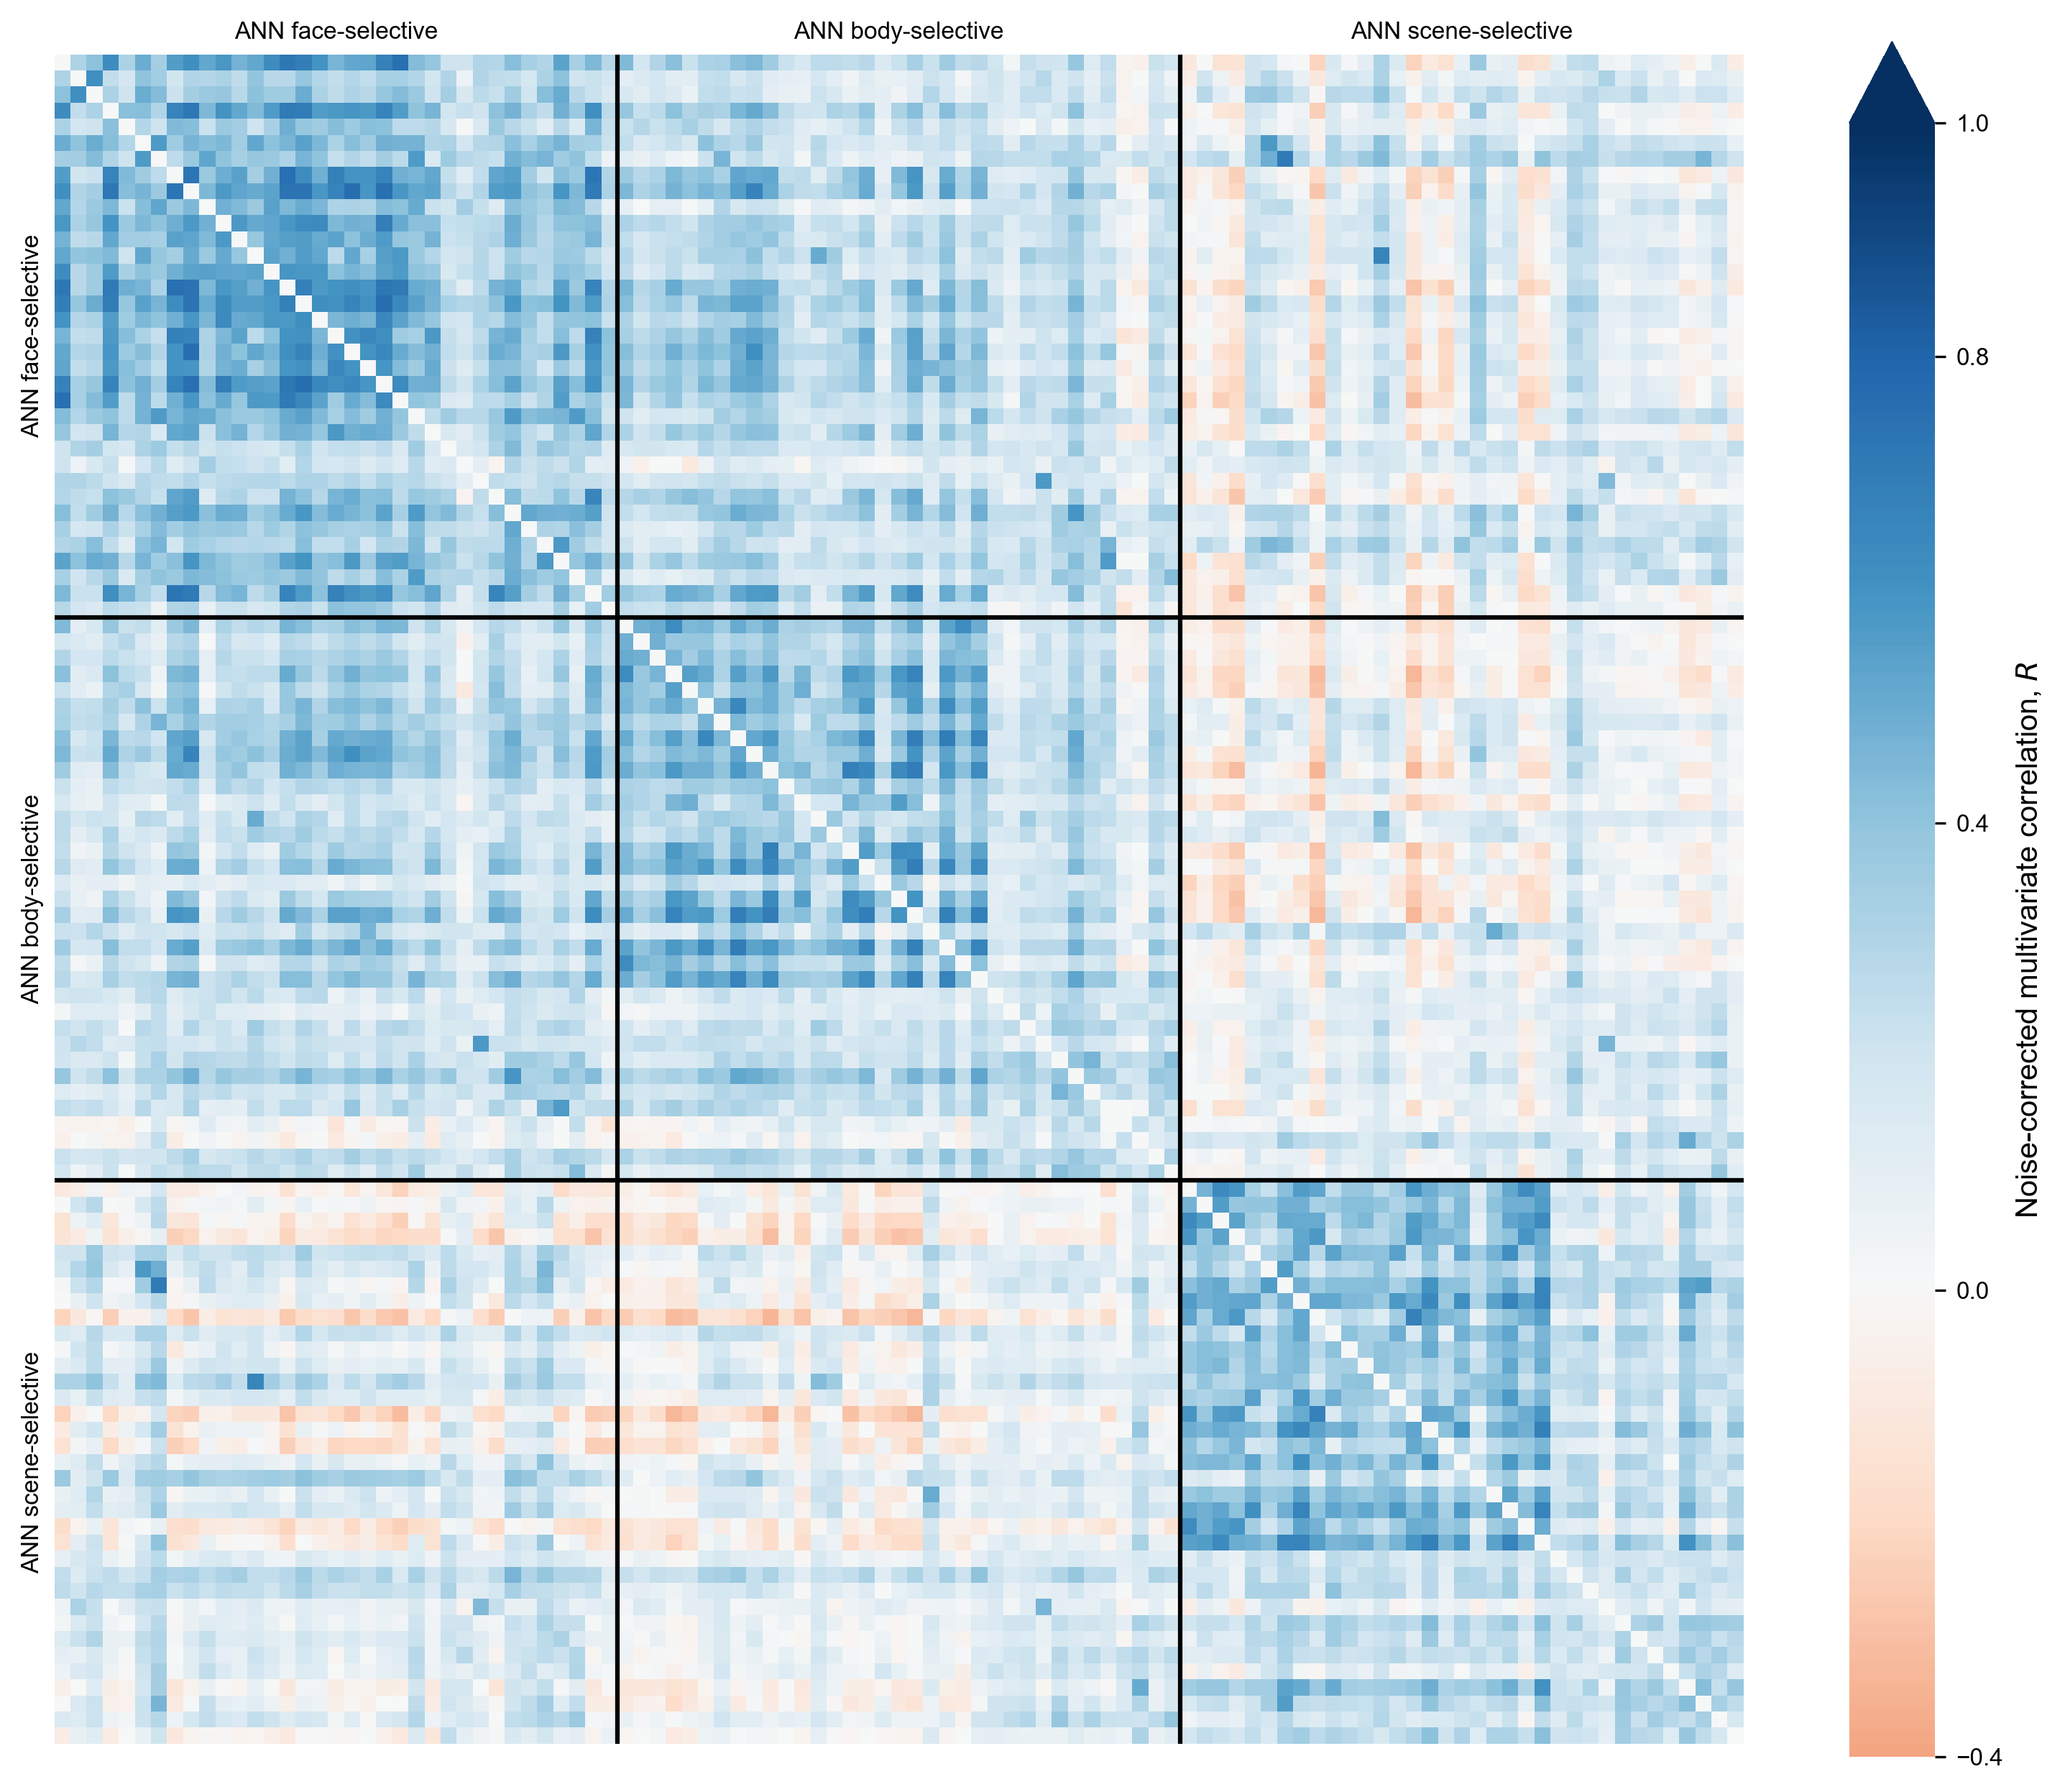

In [119]:
savefig = False
rsa_used = torch.clone(normed_rsa_rdmr)
figname = None # # f'figS4_normed_rdmr_rsa_t{tthreshold}.pdf'

# Drop OFA (index 8-15), FBA (59-66), OPA (110-117) from the heatmap to focus on the main comparisons
# Indices to drop
drop_ranges = [
    range(0, 8),       # FFA
    range(8, 16),      # OFA
    range(51, 59),     # EBA
    range(59, 67),     # FBA
    range(102, 110),   # PPA
    range(110, 118)    # OPA
]
# Flatten drop indices
drop_idx = sorted([i for r in drop_ranges for i in r])
# Create mask of indices to keep
all_idx = torch.arange(rsa_used.shape[0])
keep_mask = ~torch.isin(all_idx, torch.tensor(drop_idx))
# Apply mask to rows and columns
rsa_reduced = rsa_used[keep_mask][:, keep_mask]
rsa_used = rsa_reduced
print(f'Minimum and maximum values in the reduced RSA matrix: {rsa_used.min().item():.3f}, {rsa_used.max().item():.3f}')

vmin = -0.4
cbar_ticks = [-0.4, 0, 0.4, 0.8, 1.0]
cbar_label = r"Noise-corrected multivariate correlation, $R$"

# Plot raw rdmr rsa as heatmap
plt.figure(figsize=(10, 10), dpi=300)
vmax = 1.0  # Clamp max at 1
clamped_rsa = torch.clamp(rsa_used, min=vmin, max=vmax)
ax = sns.heatmap(clamped_rsa.cpu().numpy(), cmap='RdBu', vmin=vmin, vmax=vmax, center=0, square=True, cbar_kws={'extend': 'max', 'shrink': 0.8})
cbar = ax.collections[0].colorbar
cbar.set_ticks(cbar_ticks)
cbar.ax.tick_params(labelsize=8)
cbar.set_label(cbar_label, fontsize=10)
# Add lines to separate systems (after froi change or system type change)
system_boundaries = []
system_labels = []
current_system_type = None
current_froi = None
for idx, system_name in enumerate(ordered_keys):
    if system_name.startswith('subject_'):
        system_type = 'subjects'
        froi = system_name.split('_')[-2]  # Remove 'tthreshold'
    elif system_name.startswith('model_'):
        system_type = 'models'
        froi = system_name.split('_')[-2].split('to')[0]  # Remove 'to' and fmri_froi
    if current_system_type is None:
        current_system_type = system_type
        current_froi = froi
        # system_label = system_order[(current_system_type, current_froi)]
        # system_labels.append(system_label)
    else:
        if system_type != current_system_type or froi != current_froi:
            system_boundaries.append(idx)
            current_froi_ = froi if current_system_type == 'subjects' else (froi, froi)
            # system_label = system_order[(current_system_type, current_froi_)]
            # print(current_system_type, current_froi_, 'label= ',system_label)
            # system_labels.append(system_label)
            current_system_type = system_type
            current_froi = froi
# Add the last section label
# current_froi_ = froi if current_system_type == 'subjects' else (froi, froi)
# system_labels.append(system_order[(current_system_type, current_froi_)])
system_labels = list(system_order.values())

for sbidx, boundary in enumerate(system_boundaries):
    if (sbidx+1)%1 == 0:
        plt.axhline(boundary, color='black', linestyle='-', linewidth=1.5)
        plt.axvline(boundary, color='black', linestyle='-', linewidth=1.5)
    # else:
    #     plt.axhline(boundary, color='black', linestyle='--', linewidth=0.75)
    #     plt.axvline(boundary, color='black', linestyle='--', linewidth=0.75)
# Add system labels
midpoints = []
start_idx = 0
for boundary in system_boundaries + [len(ordered_keys)]:
    midpoint = (start_idx + boundary) / 2
    midpoints.append(midpoint)
    start_idx = boundary
plt.xticks(midpoints, system_labels, rotation=0)
plt.yticks(midpoints, system_labels, rotation=90)
plt.tick_params(axis='both', length=0, labelsize=8)
# Place x-axis labels on top
plt.gca().xaxis.set_ticks_position('top')
plt.gca().xaxis.set_label_position('top')
# plt.title('Normed RDMR RSA Heatmap')
# plt.xlabel('Systems')
# plt.ylabel('Systems')
plt.tight_layout(pad=0.2)
if savefig:
    plt.savefig(f'{plots_dir}/{figname}', dpi=300, transparent=True) # , bbox_inches='tight'
else:
    plt.show()
plt.close()

Total models: 35, CNNs: 23, ViTs: 12


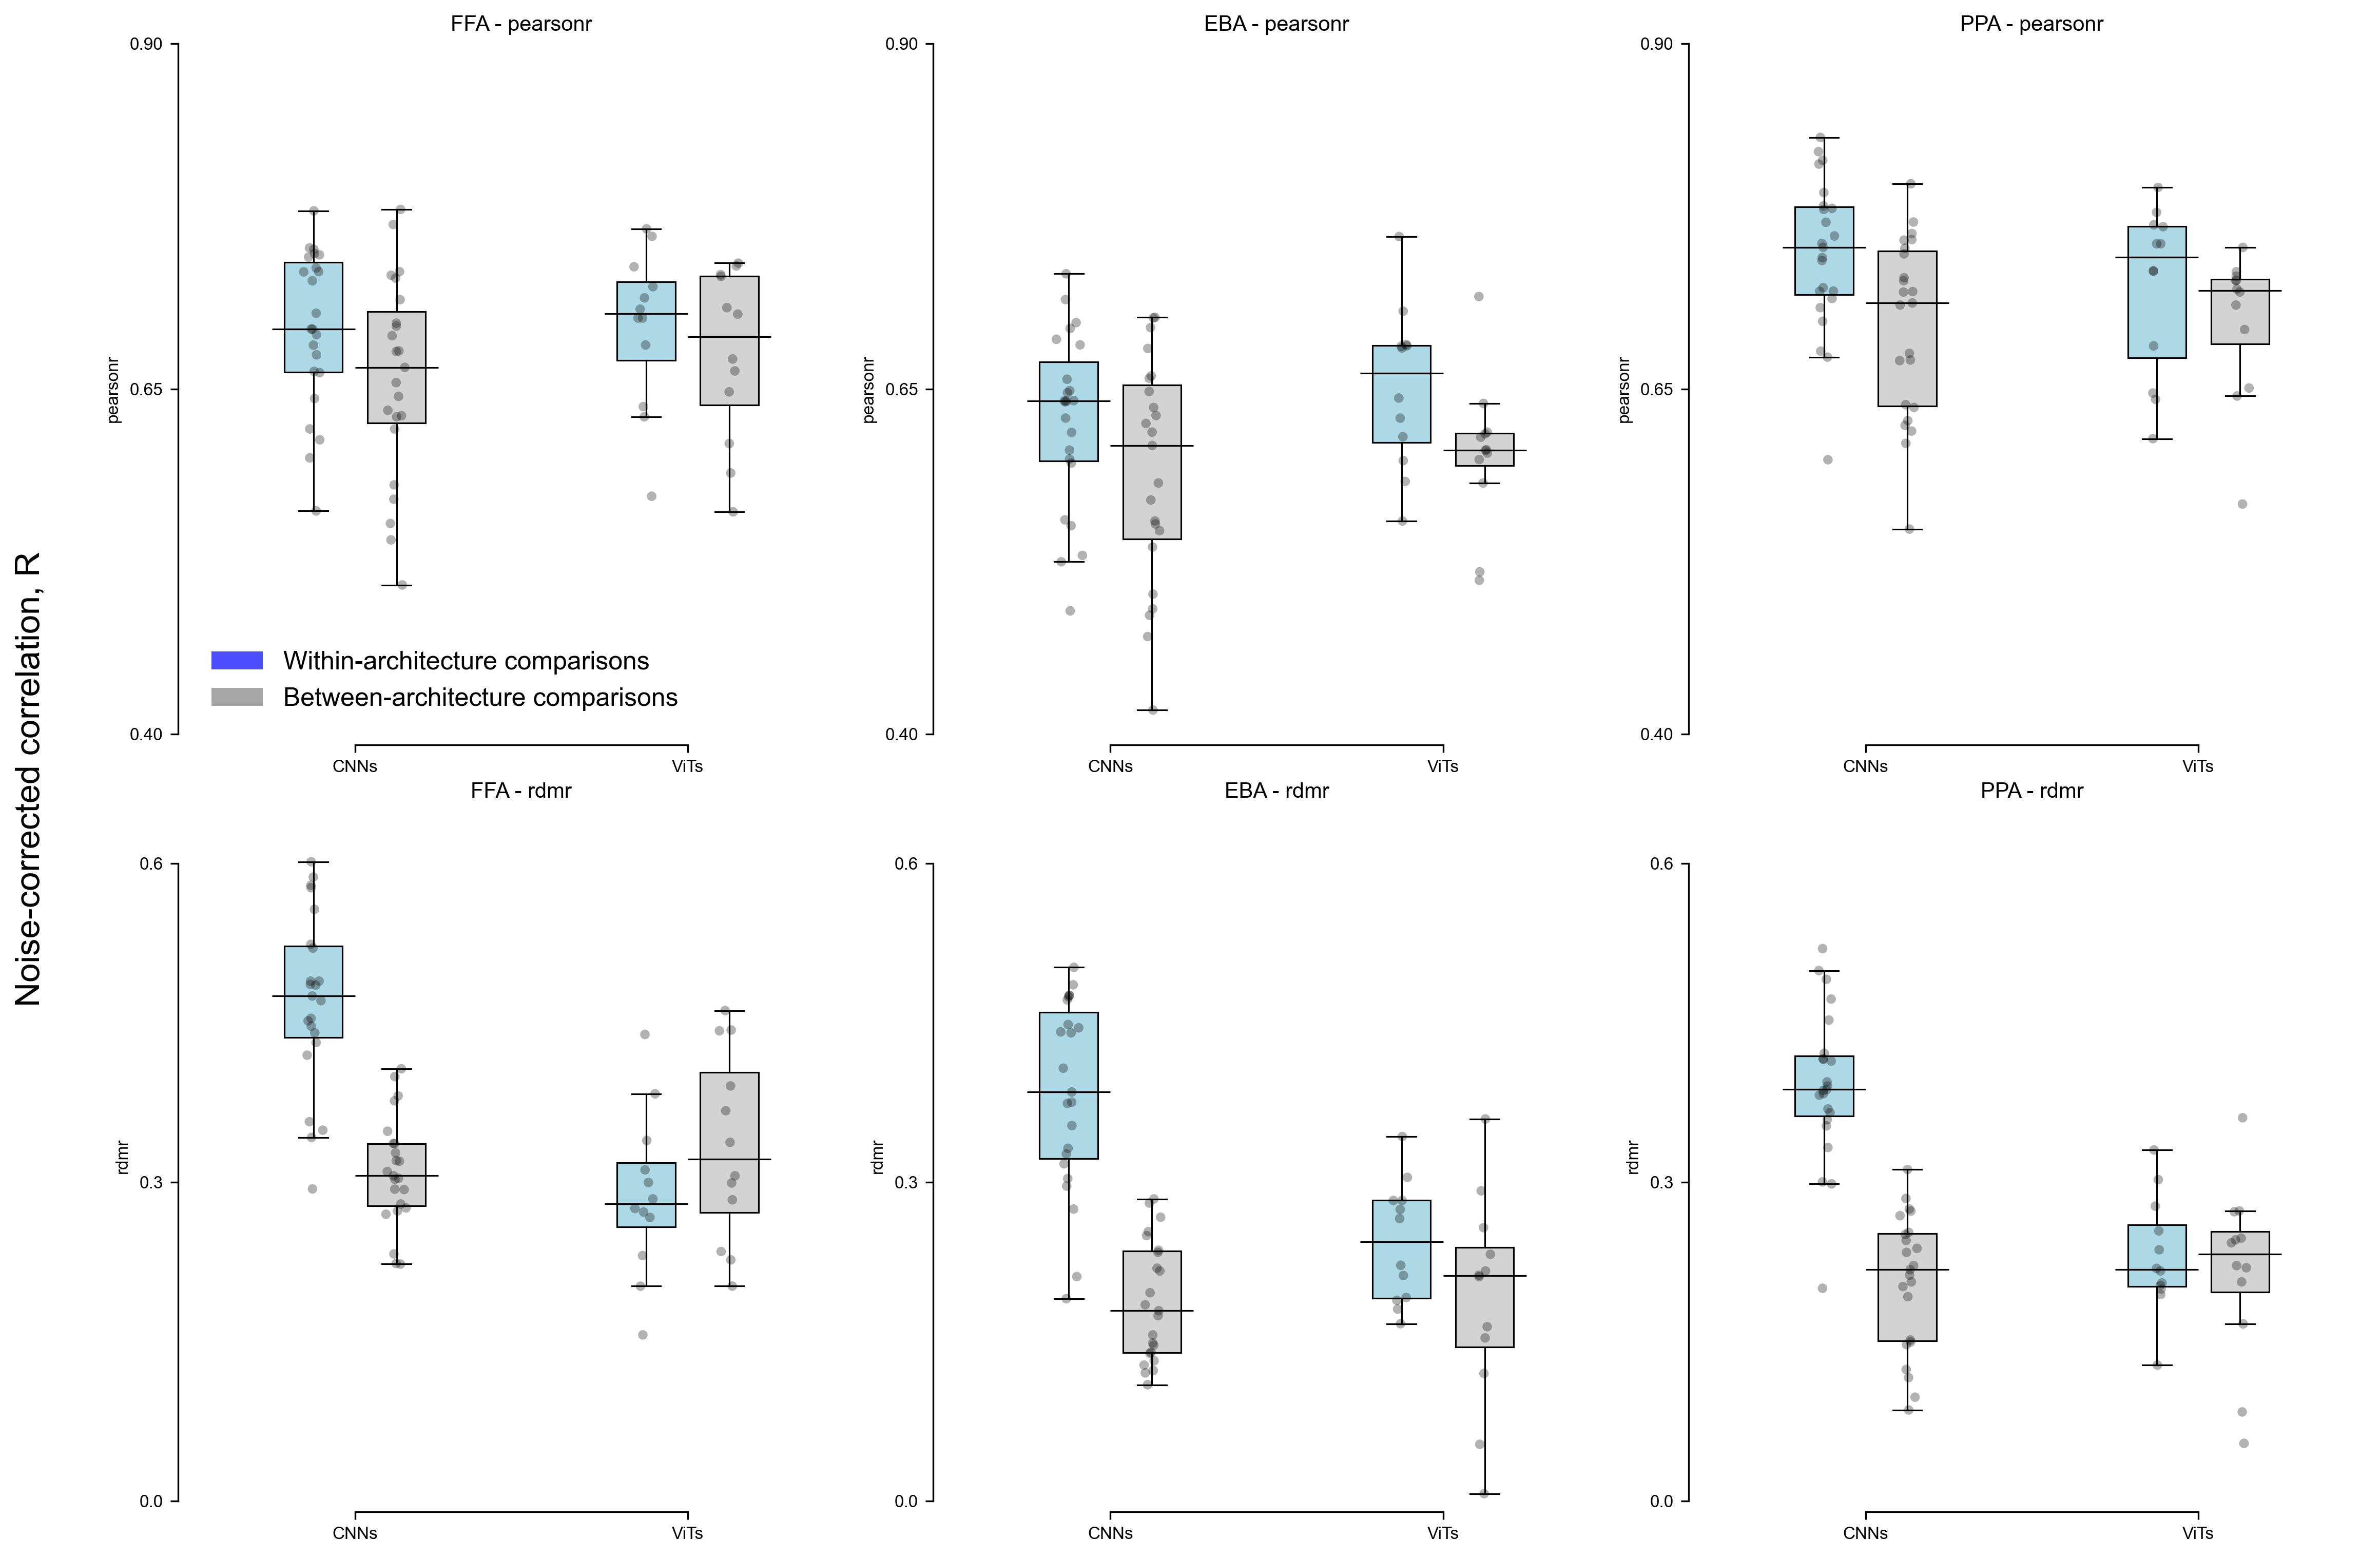

In [120]:
savefig = False

n_total_models = len(model_names)
n_cnns = len([m for m in model_names if 'vit' not in m])
n_vits = len([m for m in model_names if 'vit' in m])
print(f'Total models: {n_total_models}, CNNs: {n_cnns}, ViTs: {n_vits}')
# Make a plot with 3 subplots for FFA, EBA, PPA, showing the correlations within architecture type (CNN vs ViT) for the model-subject comparisons
# For each figure have architecture on x-axis and correlation on y-axis, for each xtick have 2 boxplots (one for within-architecture comparisons and one for between-architecture comparisons), and scatter points for each model. Each point should be the model's correlation median with all other models considered in the same category (CNN or ViT) for the within-architecture comparisons, and with all models considered in the different category for the between-architecture comparisons. Conduct t-tests between the within-architecture and between-architecture comparisons for each architecture type and annotate the plots with the p-values.
frois = ['FFA', 'EBA', 'PPA']
arch_types = ['CNNs', 'ViTs']
metrics_data_dict = {
    'pearsonr': normed_rsa_pearsonr,
    'rdmr': normed_rsa_rdmr,
}
metric_lims_ticks = {
    'pearsonr': {
        'ylim': (0.4, 0.9),
        'yticks': [0.4, 0.65, 0.9]
    },
    'rdmr': {
        'ylim': (0, 0.65),
        'yticks': [0, 0.3, 0.6]
    },
}
fig, axs = plt.subplots(len(metrics_data_dict), len(frois), figsize=(5*len(frois), 5*len(metrics_data_dict)), dpi=300)
box_data_frois = {}
for midx, (metric, rsa_used) in enumerate(metrics_data_dict.items()):
    rsa_used = metrics_data_dict[metric]
    # Indices to drop
    drop_ranges = [
        range(0, 8),       # FFA
        range(8, 16),      # OFA
        range(51, 59),     # EBA
        range(59, 67),     # FBA
        range(102, 110),   # PPA
        range(110, 118)    # OPA
    ]
    # Flatten drop indices
    drop_idx = sorted([i for r in drop_ranges for i in r])
    # Create mask of indices to keep
    all_idx = torch.arange(rsa_used.shape[0])
    keep_mask = ~torch.isin(all_idx, torch.tensor(drop_idx))
    # Apply mask to rows and columns
    rsa_reduced = rsa_used[keep_mask][:, keep_mask]
    rsa_used = rsa_reduced
    for fidx, froi in enumerate(frois):
        froi_keys = [k for k in ordered_keys if froi in k]
        rsa_used_froi = torch.clone(rsa_used)
        ax_current = axs[midx, fidx]
        rsa_used_froi = rsa_used_froi[n_total_models*fidx : n_total_models*(fidx+1)]
        rsa_used_froi = rsa_used_froi[:, n_total_models*fidx : n_total_models*(fidx+1)]
        # Separate within-architecture and between-architecture comparisons
        cnns_within, vits_within, cnns_across, vits_across = [], [], [], []
        # cnns_within is CNN-CNN
        # vits_within is ViT-ViT
        # cnns_across is CNN-ViT for CNNs
        # vits_across is ViT-CNN for ViTs
        for model_name in model_names:
            model_data = rsa_used_froi[froi_keys.index(f'model_{model_name}_{froi}to{froi}_t{tthreshold}')]
            if 'vit' in model_name:
                # ViT model
                # For within ViTs, take median correlation with all other ViTs (excluding self)
                vits_within_data = model_data[[froi_keys.index(f'model_{m}_{froi}to{froi}_t{tthreshold}') for m in model_names if 'vit' in m and m != model_name]]
                assert len(vits_within_data) == n_vits - 1, f"Expected {n_vits-1} within-ViT comparisons, got {len(vits_within_data)}"
                vits_within.append(vits_within_data.median())
                # For between ViTs, take median correlation with all CNNs
                # vits_across.append(model_data[[ordered_keys.index(f'model_{m}_{froi}to{froi}_t{tthreshold}') for m in model_names if 'vit' not in m]].median())
                vits_across_data = model_data[[froi_keys.index(f'model_{m}_{froi}to{froi}_t{tthreshold}') for m in model_names if 'vit' not in m]]
                assert len(vits_across_data) == n_cnns, f"Expected {n_cnns} between-architecture comparisons for ViT, got {len(vits_across_data)}"
                vits_across.append(vits_across_data.median())
            else:
                # CNN model
                # For within CNNs, take median correlation with all other CNNs (excluding self)
                cnns_within_data = model_data[[froi_keys.index(f'model_{m}_{froi}to{froi}_t{tthreshold}') for m in model_names if 'vit' not in m and m != model_name]]
                assert len(cnns_within_data) == n_cnns - 1, f"Expected {n_cnns-1} within-CNN comparisons, got {len(cnns_within_data)}"
                cnns_within.append(cnns_within_data.median())
                # For between CNNs, take median correlation with all ViTs                
                cnns_across_data = model_data[[froi_keys.index(f'model_{m}_{froi}to{froi}_t{tthreshold}') for m in model_names if 'vit' in m]]
                assert len(cnns_across_data) == n_vits, f"Expected {n_vits} between-architecture comparisons for CNN, got {len(cnns_across_data)}"
                cnns_across.append(cnns_across_data.median())
        # Assert that we have the expected number of comparisons
        assert len(cnns_within) == n_cnns, f"Expected {n_cnns-1} within-CNN comparisons, got {len(cnns_within)}"
        assert len(cnns_across) == n_cnns, f"Expected {n_cnns} between-architecture comparisons for CNN, got {len(cnns_across)}"
        assert len(vits_within) == n_vits, f"Expected {n_vits-1} within-ViT comparisons, got {len(vits_within)}"
        assert len(vits_across) == n_vits, f"Expected {n_vits} between-architecture comparisons for ViT, got {len(vits_across)}"

        # Convert to numpy arrays for plotting and stats
        within_cnns = np.array(cnns_within)
        within_vits = np.array(vits_within)
        between_cnns = np.array(cnns_across)
        between_vits = np.array(vits_across)

        # Prepare data for boxplots
        box_data = [within_cnns, between_cnns, within_vits, between_vits]
        labels = ['Within CNNs', 'Between CNNs', 'Within ViTs', 'Between ViTs']
        colors = ['lightblue', 'lightgray', 'lightblue', 'lightgray']
        box_data_frois[(metric, froi)] = box_data
        
        # Box plot
        linewidth = 0.75
        barwidth = 0.35
        x_positions = [-0.25, 0.25, 1.75, 2.25]
        boxes = ax_current.boxplot(
                    box_data, positions=x_positions, patch_artist=True, 
                    widths=barwidth, showfliers=False,
                    boxprops={'color': 'black', 'linewidth': linewidth},
                    whiskerprops=dict(linewidth=linewidth),
                    capprops=dict(linewidth=linewidth),
                    medianprops={'color': 'black', 'linewidth': linewidth},
                    flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
                )
        for i, data in enumerate(box_data):
            med = np.median(data)
            x = x_positions[i]
            ax_current.plot([x - 0.25, x + 0.25], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
        for box, color in zip(boxes['boxes'], colors):
            box.set(facecolor=color)
        # Scatter points
        jitter_scale = 0.025
        markersize = 20
        x_within_cnns = np.ones(len(within_cnns))*x_positions[0] + np.random.normal(0, jitter_scale, len(within_cnns)) 
        x_between_cnns = np.ones(len(between_cnns))*x_positions[1] + np.random.normal(0, jitter_scale, len(between_cnns))
        x_within_vits = np.ones(len(within_vits))*x_positions[2] + np.random.normal(0, jitter_scale, len(within_vits))
        x_between_vits = np.ones(len(between_vits))*x_positions[3] + np.random.normal(0, jitter_scale, len(between_vits))
        ax_current.scatter(x_within_cnns, within_cnns, color='k', alpha=0.3, zorder=5, edgecolors='none', s=markersize)
        ax_current.scatter(x_between_cnns, between_cnns, color='k', alpha=0.3, zorder=5, edgecolors='none', s=markersize)
        ax_current.scatter(x_within_vits, within_vits, color='k', alpha=0.3, zorder=5, edgecolors='none', s=markersize)
        ax_current.scatter(x_between_vits, between_vits, color='k', alpha=0.3, zorder=5, edgecolors='none', s=markersize)
        # Conduct t-tests
        # t_within_cnns, p_within_cnns = scipy.stats.ttest_ind(within_cnns, between_cnns, equal_var=False)
        # t_within_vits, p_within_vits = scipy.stats.ttest_ind(within_vits, between_vits, equal_var=False)
        # print(f'{metric} - {froi} - Within CNNs: t={t_within_cnns:.2f}, p={p_within_cnns:.2e}; Within ViTs: t={t_within_vits:.2f}, p={p_within_vits:.2e}')
        # # Annotate p-values
        # y_max = max(within_cnns.max(), between_cnns.max(), within_vits.max(), between_vits.max())
        # y_min = min(within_cnns.min(), between_cnns.min(), within_vits.min(), between_vits.min())
        # y_range = y_max - y_min
        # y_offset = y_range * 0.1
        # # Annotate within CNNs
        # x1, x2 = 0, 1
        # y = max(within_cnns.max(), between_cnns.max()) + y_offset
        # ax_current.plot([x1, x1, x2, x2], [y, y+y_offset*0.2, y+y_offset*0.2, y], color='black', linewidth=linewidth)
        # ax_current.text((x1+x2)/2, y+y_offset*0.2, f'p={p_within_cnns:.2e}', ha='center', va='bottom', fontsize=8)
        # Annotate within ViTs
        # x1, x2 = 3, 4
        # y = max(within_vits.max(), between_vits.max()) + y_offset
        # ax_current.plot([x1, x1, x2, x2], [y, y+y_offset*0.2, y+y_offset*0.2, y], color='black', linewidth=linewidth)
        # ax_current.text((x1+x2)/2, y+y_offset*0.2, f'p={p_within_vits:.2e}', ha='center', va='bottom', fontsize=8)
        # Set x-axis labels and limits
        # Legend just annotating which color corresponds to which comparison type
        ax_current.set_xticks([0, 2])
        ax_current.set_xticklabels(['CNNs', 'ViTs'])
        ax_current.set_xlim(-1, 3)
        ax_current.set_title(f'{froi} - {metric}', fontsize=10)
        ax_current.set_ylabel(metric, fontsize=8)
        ax_current.tick_params(axis='x', labelsize=8)
        ax_current.tick_params(axis='y', labelsize=8)
        ax_current.set_ylim(metric_lims_ticks[metric]['ylim'])
        ax_current.set_yticks(metric_lims_ticks[metric]['yticks'])
        ax_current.spines['top'].set_visible(False)
        ax_current.spines['right'].set_visible(False)
        ax_current.spines['bottom'].set_position(('outward', 5))
        ax_current.spines['left'].set_position(('outward', 5))
        ax_current.spines['bottom'].set_bounds(0, 2)
        ax_current.spines['left'].set_bounds(metric_lims_ticks[metric]['yticks'][0], metric_lims_ticks[metric]['yticks'][-1])
        if midx == 0 and fidx == 0:
            legend_elements = [
                Patch(facecolor='blue', alpha=0.7,
                    label='Within-architecture comparisons'),
                Patch(facecolor='gray', alpha=0.7,
                    label='Between-architecture comparisons'),
            ]

            ax_current.legend(
                handles=legend_elements,
                loc='lower left',
                fontsize=12,
                frameon=False
            )
fig.supylabel('Noise-corrected correlation, R', fontsize=16, x=-0.02)
plt.tight_layout(pad=0.3)
if savefig:
    plt.savefig(f'{plots_dir}/figS5_within_between_architecture_comparisons.pdf', dpi=300, transparent=True) # , bbox_inches='tight'
else:    
    plt.show()
plt.close()

## Generate RDM data (and MDS dev)

In [6]:
# Util functions
def calculate_stress(original_distances, projected_distances):
    """
    Calculate the Kruskal's Stress between two distance matrices.
    
    Args:
    original_distances (torch.Tensor): The original distance matrix (n x n).
    projected_distances (torch.Tensor): The distance matrix after MDS (n x n).
    
    Returns:
    torch.Tensor: The stress value.
    """
    # Compute the squared differences between the original and projected distances
    diff = original_distances - projected_distances
    squared_diff = diff ** 2
    
    # Calculate the sum of squared differences
    numerator = torch.sum(squared_diff)
    
    # Calculate the sum of squared original distances
    denominator = torch.sum(original_distances ** 2)
    
    # Calculate stress
    stress = torch.sqrt(numerator / denominator)
    
    return stress.item()

tthreshold = 7
fmri_frois = ['FFA', 'OFA', 'PPA', 'OPA', 'EBA', 'FBA']
model_localizer = 'grillspector'
model_fmri_frois = [
    ('FFA', 'FFA'),
    ('PPA', 'PPA'),
    ('EBA', 'EBA'),
]
taskoptimized_model_names = ma.get_model_names('task_optimized')

In [7]:
# Get data
subjects_data, subjects_splithalf_pearsonrs, subjects_splithalf_rdmrs = \
    ma.get_allsubjects_nsd515_data(fmri_frois, tthreshold)
# for froi in subjects_data.keys():
#     for subject in subjects_data[froi].keys():
#         subjects_data[froi][subject] = subjects_data[froi][subject].mean(axis=-1).cuda()
models_data = ma.get_allmodels_nsd515_data(
    model_fmri_frois, tthreshold, model_localizer, unitmean=False
)

Getting model data: alexnetimagenet1kv1, layer: features.11, model_froi: FFA, fmri_froi: FFA


Using cache found in /Users/adipani3/.cache/torch/hub/harvard-visionlab_open_ipcl_main


Getting model data: alexnetipclref01, layer: conv_block_5.1, model_froi: FFA, fmri_froi: FFA
Getting model data: alexnetbarlowtwins, layer: backbone.4.1, model_froi: FFA, fmri_froi: FFA
Getting model data: vgg16imagenet1kv1, layer: features.30, model_froi: FFA, fmri_froi: FFA
Getting model data: resnet18imagenet1kv1, layer: layer4.1.relu1, model_froi: FFA, fmri_froi: FFA
Getting model data: resnet18tdannsupervisedlw10, layer: layer4.1.bn1, model_froi: FFA, fmri_froi: FFA
Getting model data: resnet18tdannsimclrlw1, layer: layer4.1.conv1, model_froi: FFA, fmri_froi: FFA
Getting model data: resnet50imagenet1kv2, layer: layer4.0.relu3, model_froi: FFA, fmri_froi: FFA
Getting model data: resnet50openaiclip, layer: layer4.1.relu1, model_froi: FFA, fmri_froi: FFA
/Users/adipani3/.cache/torch/checkpoints/1a6IO4xhWy8cdyAuWv0BxSONz7lMcKbZE.pth.tar
Getting model data: resnet50simclr, layer: avgpool, model_froi: FFA, fmri_froi: FFA
Getting model data: resnet50robustl2eps3, layer: layer4.1.relu2, m

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/torch/amp/grad_scaler.py:136: UserWarning: torch.cuda.amp.GradScaler is enabled, but CUDA is not available.  Disabling.
  warnings.warn(
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Getting model data: resnet50toponettau30, layer: layer4.1.relu3, model_froi: FFA, fmri_froi: FFA
Getting model data: resnet50cesslbarlowtop, layer: layer4.1.bn1, model_froi: FFA, fmri_froi: FFA
Getting model data: resnet50blurstrong, layer: layer4.1.relu2, model_froi: FFA, fmri_froi: FFA
Getting model data: resnet101imagenet1kv1, layer: layer3.22.relu1, model_froi: FFA, fmri_froi: FFA
Getting model data: resnet101openaiclip, layer: layer4.1.relu1, model_froi: FFA, fmri_froi: FFA
Getting model data: bagnet33, layer: layer4.1.relu1, model_froi: FFA, fmri_froi: FFA
Getting model data: cornets, layer: V4.nonlin2, model_froi: FFA, fmri_froi: FFA
Getting model data: cornetz, layer: IT.pool, model_froi: FFA, fmri_froi: FFA
Getting model data: convnexttinyimagenet1kv1, layer: features.5.7.block.3, model_froi: FFA, fmri_froi: FFA
Getting model data: vitb32imagenet1kv1, layer: encoder.layers.encoder_layer_8.mlp, model_froi: FFA, fmri_froi: FFA
Getting model data: vitb32openaiclip, layer: transfo

...

Getting model data: vitb32dreamsimopenclip, layer: blocks.8.attn, model_froi: EBA, fmri_froi: EBA
Getting model data: vitb16imagenet21k, layer: blocks.7.attn, model_froi: EBA, fmri_froi: EBA
Getting model data: vitb16openaiclip, layer: transformer.resblocks.7.attn, model_froi: EBA, fmri_froi: EBA
Getting model data: vitb16siglip2res224, layer: trunk.blocks.6.attn, model_froi: EBA, fmri_froi: EBA
Getting model data: vitb16eva028bs8bb131k, layer: trunk.blocks.7.attn, model_froi: EBA, fmri_froi: EBA
Getting model data: vitb16synclr, layer: blocks.11.norm2, model_froi: EBA, fmri_froi: EBA


Using cache found in /Users/adipani3/.cache/torch/hub/facebookresearch_dinov2_main


Getting model data: vitb14dinov2, layer: blocks.11.attn, model_froi: EBA, fmri_froi: EBA


Using cache found in /Users/adipani3/.cache/torch/hub/facebookresearch_dinov2_main


Getting model data: vitb14dinov2reg, layer: blocks.9.norm2, model_froi: EBA, fmri_froi: EBA
Getting model data: vitl14openaiclip, layer: transformer.resblocks.10.attn, model_froi: EBA, fmri_froi: EBA
Getting model data: vitl14kosmos2, layer: encoder.layers.13.self_attn, model_froi: EBA, fmri_froi: EBA


In [8]:
# Make folders for saving results
results_dir = f'{PLOTS_DIR}/fig3/data'
plots_dir = f'{PLOTS_DIR}/fig3/mds'
os.makedirs(results_dir, exist_ok=True)
os.makedirs(plots_dir, exist_ok=True)

In [ ]:
system_order = [
    ('subjects', 'FFA'),
    ('subjects', 'OFA'),
    ('models', ('FFA', 'FFA')),
    ('subjects', 'EBA'),
    ('subjects', 'FBA'),
    ('models', ('EBA', 'EBA')),
    ('subjects', 'PPA'),
    ('subjects', 'OPA'),
    ('models', ('PPA', 'PPA')),
]

# Gather ordered responses in a single dictionary
ordered_responses = {}
for system, froi_info in system_order:
    if system == 'subjects':
        froi = froi_info
        # Get data
        froi_data = subjects_data[froi]
        for subject_number, subject_response in froi_data.items():
            ordered_responses[f'subject_{subject_number}_{froi}_t{tthreshold}'] = subject_response.to(DEVICE)
    elif system == 'models':
        model_froi = froi_info[0]
        fmri_froi = froi_info[1]
        # Get data
        froi_data = models_data[(model_froi, fmri_froi)]
        for model_name, model_response in froi_data.items():
            ordered_responses[f'model_{model_name}_{model_froi}to{fmri_froi}_t{tthreshold}'] = model_response.to(DEVICE)

# Create ordered RSA matrices (for pearsonr and rdmr)

In [57]:
# Gather split-half reliabilities in a single dictionary
ordered_splithalf_pearsonr = {}
ordered_splithalf_rdmr = {}
for system, froi_info in system_order:
    if system == 'subjects':
        froi = froi_info
        # Get data
        froi_splithalf_pearsonrs = subjects_splithalf_pearsonrs[froi]
        froi_splithalf_rdmrs = subjects_splithalf_rdmrs[froi]
        for subject_number, splithalf_pearsonr in froi_splithalf_pearsonrs.items():
            ordered_splithalf_pearsonr[f'subject_{subject_number}_{froi}_t{tthreshold}'] = splithalf_pearsonr
        for subject_number, splithalf_rdmr in froi_splithalf_rdmrs.items():
            ordered_splithalf_rdmr[f'subject_{subject_number}_{froi}_t{tthreshold}'] = splithalf_rdmr
    elif system == 'models':
        model_froi = froi_info[0]
        fmri_froi = froi_info[1]
        for model_name, model_response in froi_data.items():
            ordered_splithalf_pearsonr[f'model_{model_name}_{model_froi}to{fmri_froi}_t{tthreshold}'] = 1
            ordered_splithalf_rdmr[f'model_{model_name}_{model_froi}to{fmri_froi}_t{tthreshold}'] = 1

# Create noise-correction matrices (for pearsonr and rdmr)
ordered_noisecorrection_pearsonr_matrix = torch.zeros((len(ordered_responses), len(ordered_responses)))
ordered_noisecorrection_rdmr_matrix = torch.zeros((len(ordered_responses), len(ordered_responses)))
for i, key_i in enumerate(ordered_responses.keys()):
    for j, key_j in enumerate(ordered_responses.keys()):
        reliabiliy_i_pearsonr = ordered_splithalf_pearsonr[key_i]
        reliabiliy_j_pearsonr = ordered_splithalf_pearsonr[key_j]
        noisecorrection_pearsonr = np.sqrt(reliabiliy_i_pearsonr * reliabiliy_j_pearsonr)
        ordered_noisecorrection_pearsonr_matrix[i, j] = noisecorrection_pearsonr

        reliabiliy_i_rdmr = ordered_splithalf_rdmr[key_i]
        reliabiliy_j_rdmr = ordered_splithalf_rdmr[key_j]
        noisecorrection_rdmr = np.sqrt(reliabiliy_i_rdmr * reliabiliy_j_rdmr)
        ordered_noisecorrection_rdmr_matrix[i, j] = noisecorrection_rdmr

# Save noise-correction matrices
torch.save(ordered_noisecorrection_pearsonr_matrix, f'{results_dir}/ordered_noisecorrection_pearsonr_matrix_t{tthreshold}.pt')
torch.save(ordered_noisecorrection_rdmr_matrix, f'{results_dir}/ordered_noisecorrection_rdmr_matrix_t{tthreshold}.pt')

In [71]:
n_elements = len(ordered_responses)
ordered_raw_pearsonr_rsa = torch.zeros((n_elements, n_elements))
ordered_raw_rdmr_rsa = torch.zeros((n_elements, n_elements))
for i, (name_i, response_i) in tqdm(enumerate(ordered_responses.items()), total=n_elements):
    for j, (name_j, response_j) in enumerate(ordered_responses.items()):
        if i == j:
            continue
        pearsonr_ij = rcutils.pearsonr(response_i.mean(axis=1), response_j.mean(axis=1))
        rdmr_ij = rcutils.rdmr(response_i, response_j)
        ordered_raw_pearsonr_rsa[i, j] = pearsonr_ij
        ordered_raw_rdmr_rsa[i, j] = rdmr_ij

# Set diagonal to 1
for i in range(n_elements):
    ordered_raw_pearsonr_rsa[i, i] = 1.0
    ordered_raw_rdmr_rsa[i, i] = 1.0

# Save raw RSAs
torch.save(ordered_raw_pearsonr_rsa, f'{results_dir}/ordered_raw_pearsonr_rsa.pt')
torch.save(ordered_raw_rdmr_rsa, f'{results_dir}/ordered_raw_rdmr_rsa.pt')
# Save order information
with open(f'{results_dir}/ordered_system_names.json', 'w') as f:
    json.dump(list(ordered_responses.keys()), f)

  0%|          | 0/153 [00:00<?, ?it/s]

In [ ]:
ordered_normed_pearsonr_rsa = ordered_raw_pearsonr_rsa / ordered_noisecorrection_pearsonr_matrix
ordered_normed_rdmr_rsa = ordered_raw_rdmr_rsa / ordered_noisecorrection_rdmr_matrix

# Set diagonal to 1
for i in range(n_elements):
    ordered_normed_pearsonr_rsa[i, i] = 1.0
    ordered_normed_rdmr_rsa[i, i] = 1.0

# Save normed RSAs
torch.save(ordered_normed_pearsonr_rsa, f'{results_dir}/ordered_normed_pearsonr_rsa_t{tthreshold}.pt')
torch.save(ordered_normed_rdmr_rsa, f'{results_dir}/ordered_normed_rdmr_rsa_t{tthreshold}.pt')

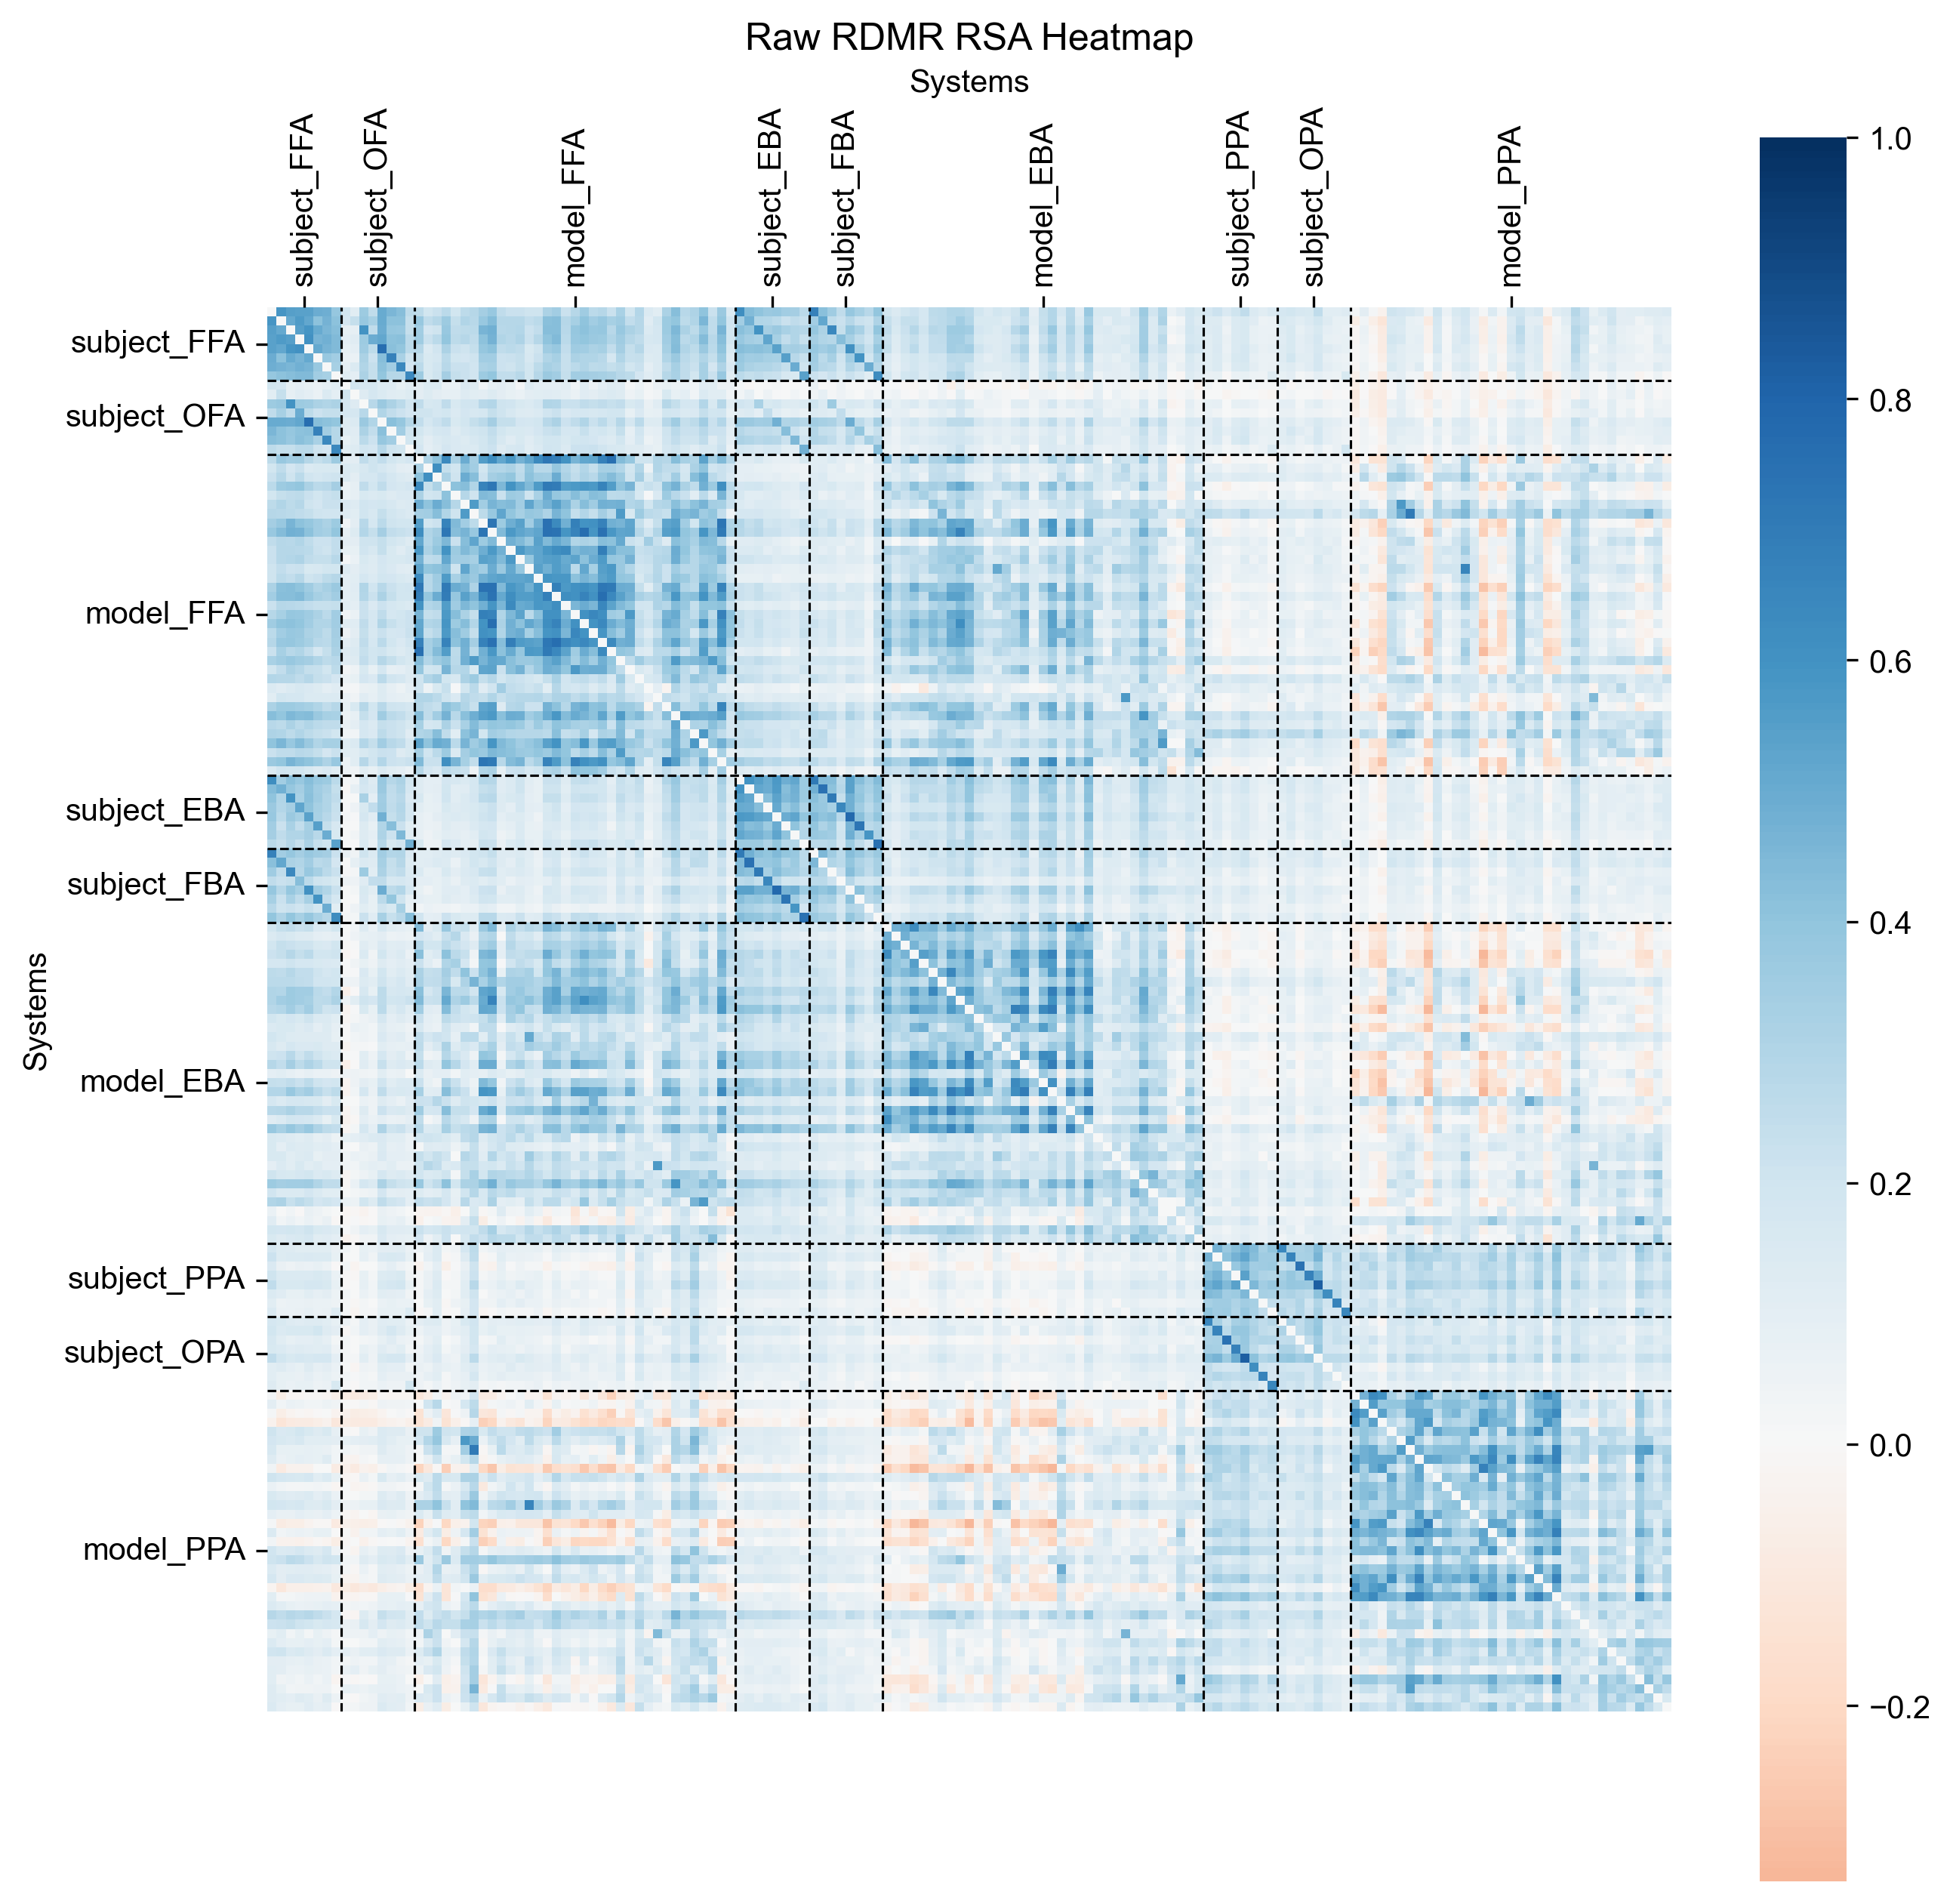

In [48]:
savefig = False

# Plot raw rdmr rsa as heatmap
plt.figure(figsize=(10, 10), dpi=300)
vmin = ordered_raw_rdmr_rsa.min().item()
vmax = ordered_raw_rdmr_rsa.max().item()
sns.heatmap(ordered_raw_rdmr_rsa.cpu().numpy(), cmap='RdBu', vmin=vmin, vmax=1, center=0, square=True)
# Add lines to separate systems (after froi change or system type change)
system_boundaries = []
system_labels = []
current_system_type = None
current_froi = None
for idx, system_name in enumerate(ordered_responses.keys()):
    if system_name.startswith('subject_'):
        system_type = 'subject'
        froi = system_name.split('_')[-2]  # Remove 'tthreshold'
    elif system_name.startswith('model_'):
        system_type = 'model'
        froi = system_name.split('_')[-2].split('to')[0]  # Remove 'to' and fmri_froi
    if current_system_type is None:
        current_system_type = system_type
        current_froi = froi
    else:
        if system_type != current_system_type or froi != current_froi:
            system_boundaries.append(idx)
            system_labels.append(f'{current_system_type}_{current_froi}')
            current_system_type = system_type
            current_froi = froi
# Add the last section label
system_labels.append(f'{current_system_type}_{current_froi}')
for boundary in system_boundaries:
    plt.axhline(boundary, color='black', linestyle='--', linewidth=0.75)
    plt.axvline(boundary, color='black', linestyle='--', linewidth=0.75)
# Add system labels
midpoints = []
start_idx = 0
for boundary in system_boundaries + [n_elements]:
    midpoint = (start_idx + boundary) / 2
    midpoints.append(midpoint)
    start_idx = boundary
plt.xticks(midpoints, system_labels, rotation=90)
plt.yticks(midpoints, system_labels, rotation=0)
# Place x-axis labels on top
plt.gca().xaxis.set_ticks_position('top')
plt.gca().xaxis.set_label_position('top')
plt.title('Raw RDMR RSA Heatmap')
plt.xlabel('Systems')
plt.ylabel('Systems')
if savefig:
    plt.savefig(f'{plots_dir}/fig3_raw_rdmr_rsa_heatmap.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()

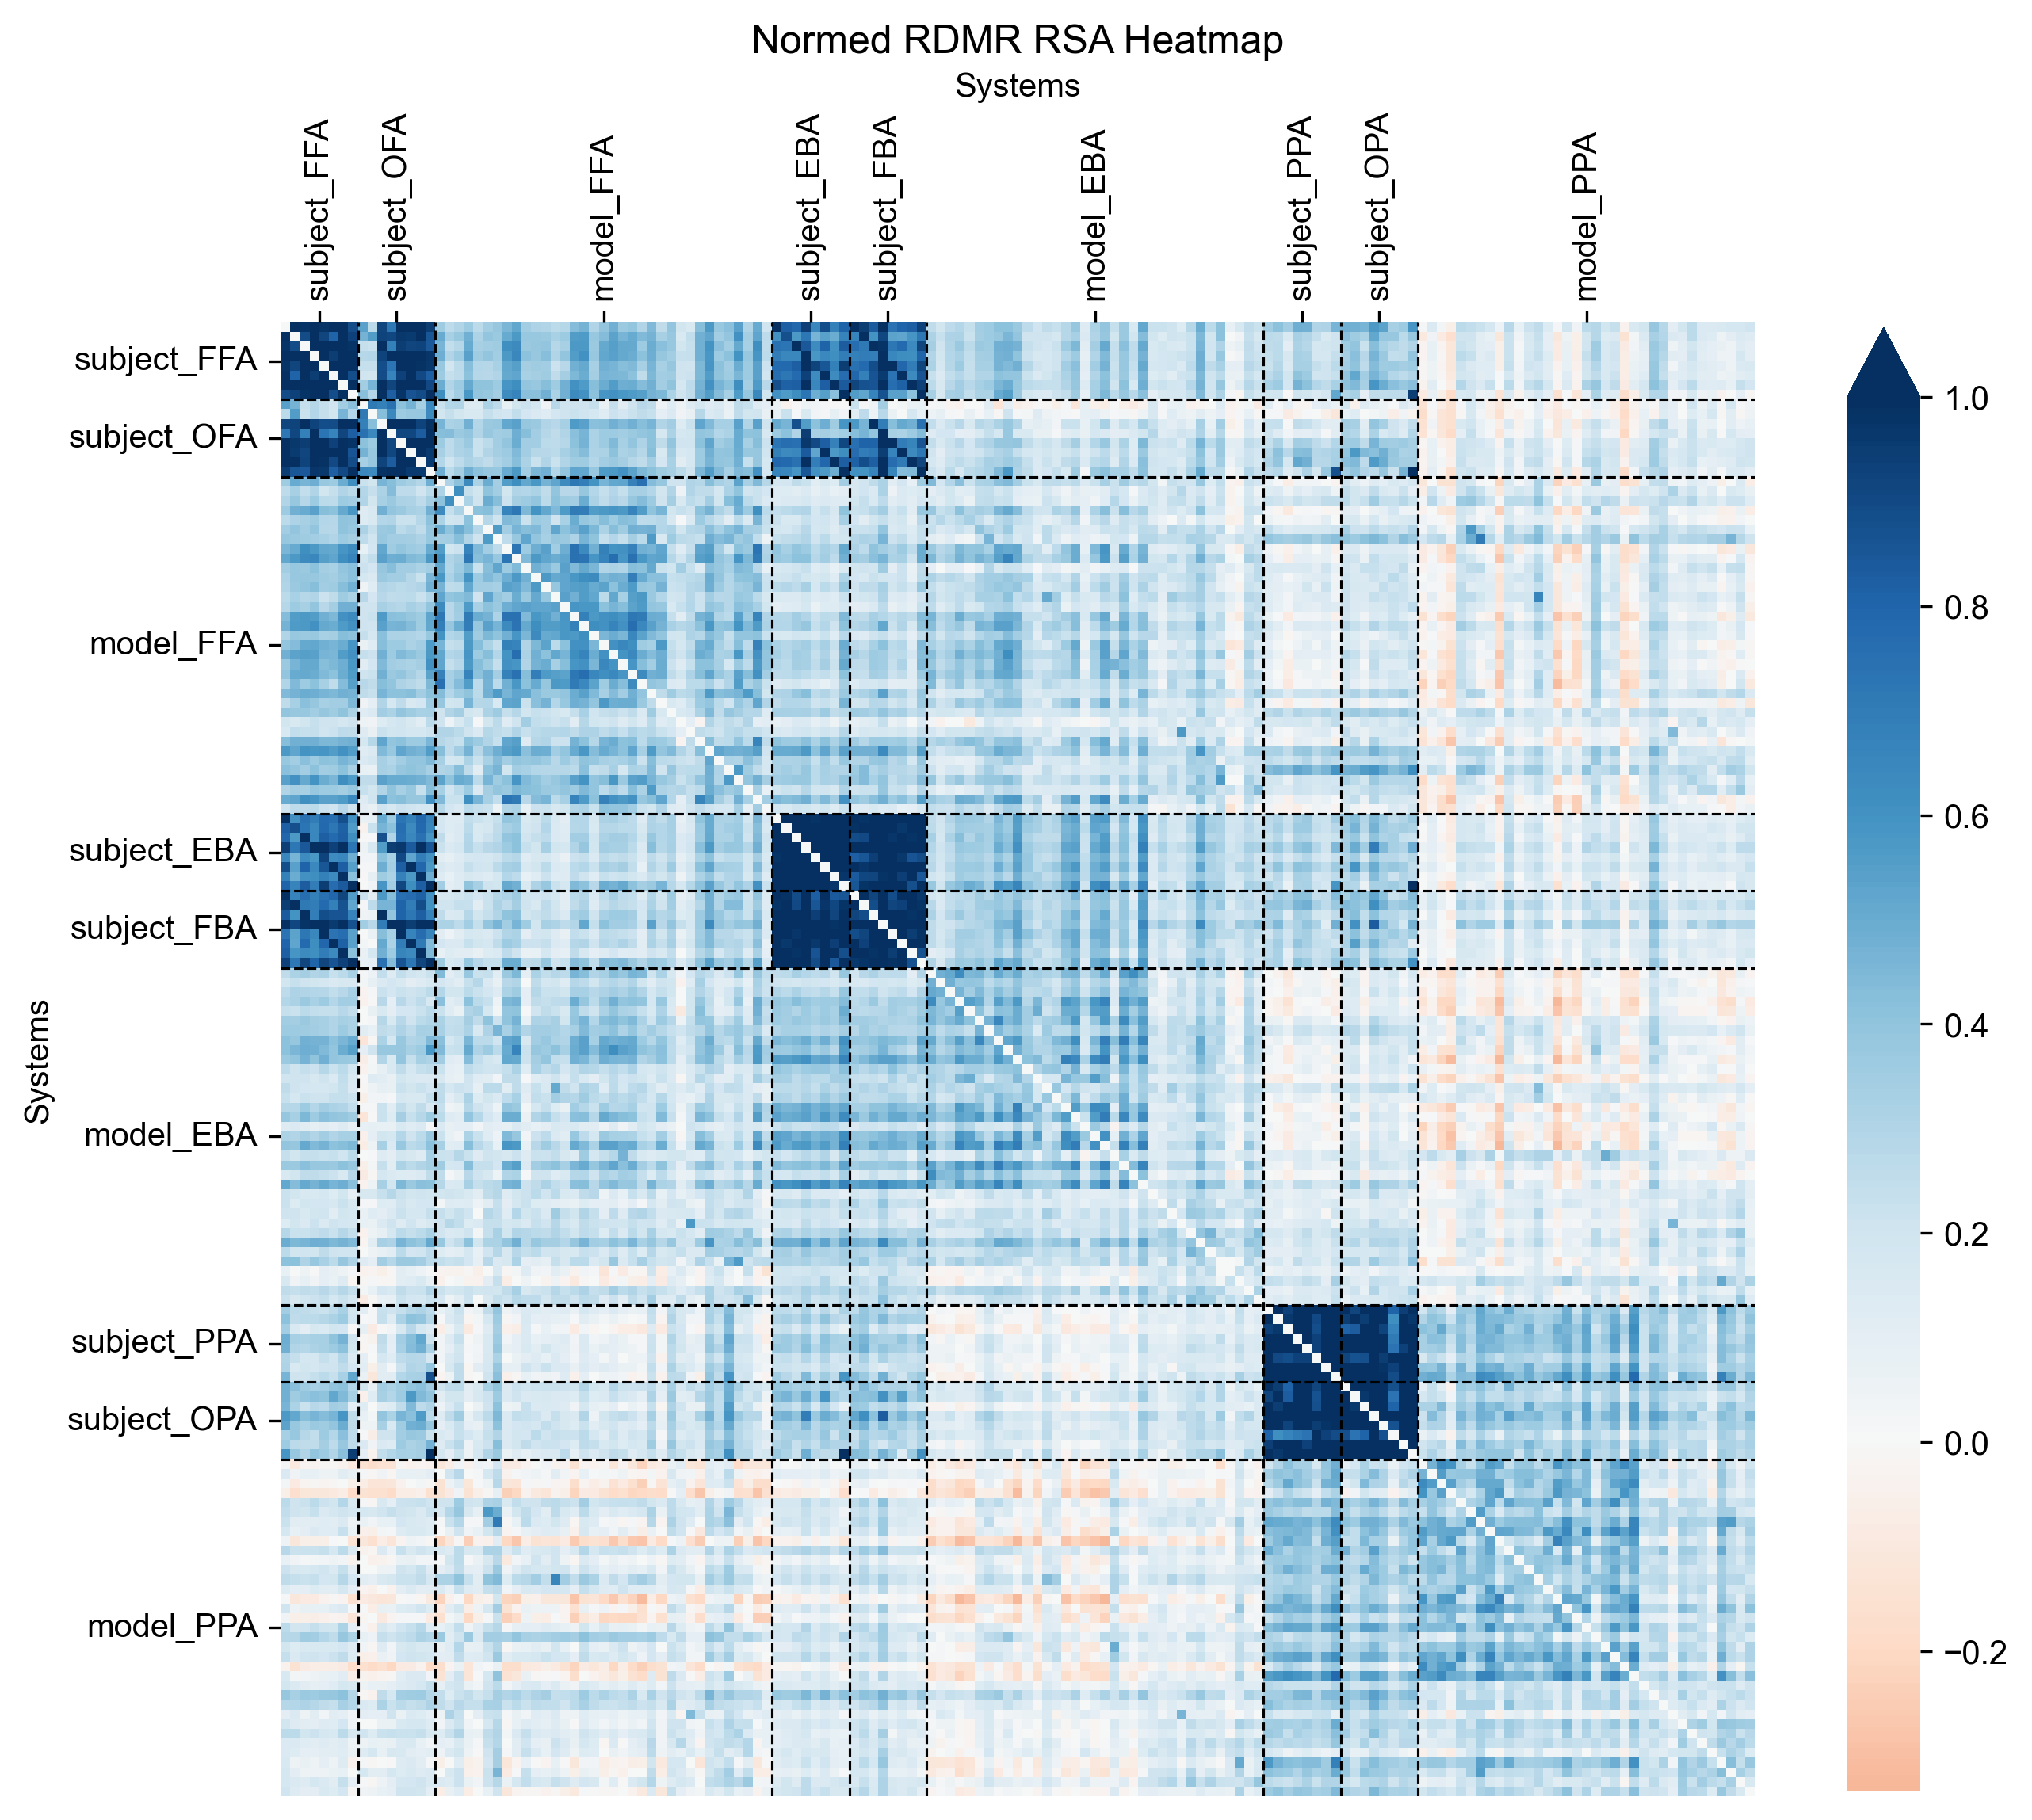

In [70]:
savefig = False

# Plot raw rdmr rsa as heatmap
plt.figure(figsize=(10, 10), dpi=300)
vmin = ordered_normed_rdmr_rsa.min().item()
vmax = 1.0  # Clamp max at 1
clamped_rsa = torch.clamp(ordered_normed_rdmr_rsa, min=vmin, max=vmax)
sns.heatmap(clamped_rsa.cpu().numpy(), cmap='RdBu', vmin=vmin, vmax=vmax, center=0, square=True, cbar_kws={'extend': 'max', 'shrink': 0.8})
# Add lines to separate systems (after froi change or system type change)
system_boundaries = []
system_labels = []
current_system_type = None
current_froi = None
for idx, system_name in enumerate(ordered_responses.keys()):
    if system_name.startswith('subject_'):
        system_type = 'subject'
        froi = system_name.split('_')[-2]  # Remove 'tthreshold'
    elif system_name.startswith('model_'):
        system_type = 'model'
        froi = system_name.split('_')[-2].split('to')[0]  # Remove 'to' and fmri_froi
    if current_system_type is None:
        current_system_type = system_type
        current_froi = froi
    else:
        if system_type != current_system_type or froi != current_froi:
            system_boundaries.append(idx)
            system_labels.append(f'{current_system_type}_{current_froi}')
            current_system_type = system_type
            current_froi = froi
# Add the last section label
system_labels.append(f'{current_system_type}_{current_froi}')
for boundary in system_boundaries:
    plt.axhline(boundary, color='black', linestyle='--', linewidth=0.75)
    plt.axvline(boundary, color='black', linestyle='--', linewidth=0.75)
# Add system labels
midpoints = []
start_idx = 0
for boundary in system_boundaries + [n_elements]:
    midpoint = (start_idx + boundary) / 2
    midpoints.append(midpoint)
    start_idx = boundary
plt.xticks(midpoints, system_labels, rotation=90)
plt.yticks(midpoints, system_labels, rotation=0)
# Place x-axis labels on top
plt.gca().xaxis.set_ticks_position('top')
plt.gca().xaxis.set_label_position('top')
plt.title('Normed RDMR RSA Heatmap')
plt.xlabel('Systems')
plt.ylabel('Systems')
if savefig:
    plt.savefig(f'{plots_dir}/fig3_normed_rdmr_rsa_heatmap.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()

In [77]:
# ordered_normed_rdmr_rsa
distances = 1 - ordered_normed_rdmr_rsa
json_file_path = f'{results_dir}/fig3_mds_normed_rdmr_t{tthreshold}.json'

mds_results = {
    'tthreshold': tthreshold,
    'model_localizer': model_localizer,
    'dataset': 'nsd515',
    'keys': list(ordered_responses.keys()),
}

epsilon = 1e-5
mds_results['epsilon'] = epsilon
print(f'{distances[distances<=0].numel()} out of {distances.numel()} values are negative, clamping to {epsilon}')
mds_results['total_negative_distances_clamped'] = distances[distances <= 0].numel()
mds_results['total_distances'] = distances.numel()
distances = torch.clamp(distances, min=epsilon)
mds = MDS(n_components=2, dissimilarity='precomputed')
mds_coords = mds.fit_transform(distances.cpu().numpy())
mds_results['mds_coordinates'] = mds_coords.tolist()

# Test if MDS distances are correct
mds_coords_tensor = torch.tensor(mds_coords)
n_systems = ordered_normed_rdmr_rsa.shape[0]
lowdim_distances = torch.zeros((n_systems, n_systems))
for i in range(n_systems):
    for j in range(i, n_systems):
        if i == j:
            continue
        dist = torch.norm(mds_coords_tensor[i] - mds_coords_tensor[j])
        lowdim_distances[i, j] = dist
stress = calculate_stress(distances, lowdim_distances)
print('Stress:', stress)
mds_results['stress'] = stress

# Calculate distances in low-dimensional MDS space, to check spearmanr with original distances
lowdim_distances_list = []
for i in range(n_systems):
    for j in range(i + 1, n_systems):
        lowdim_distances_list.append(lowdim_distances[i, j].item())
original_distances_list = []
for i in range(n_systems):
    for j in range(i + 1, n_systems):
        original_distances_list.append(distances[i, j].item())
spearmanr_corr, spearmanr_pvalue = spearmanr(original_distances_list, lowdim_distances_list)
print(f'Spearmanr between original and low-dimensional distances: {spearmanr_corr}, p-value: {spearmanr_pvalue}')
mds_results['spearmanr_original_lowdim'] = spearmanr_corr
mds_results['spearmanr_pvalue_original_lowdim'] = spearmanr_pvalue
# Save MDS results
with open(json_file_path, 'w') as f:
    json.dump(mds_results, f)

472 out of 23409 values are negative, clamping to 1e-05
Stress: 0.7377289533615112


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


Spearmanr between original and low-dimensional distances: 0.8104487634913964, p-value: 0.0


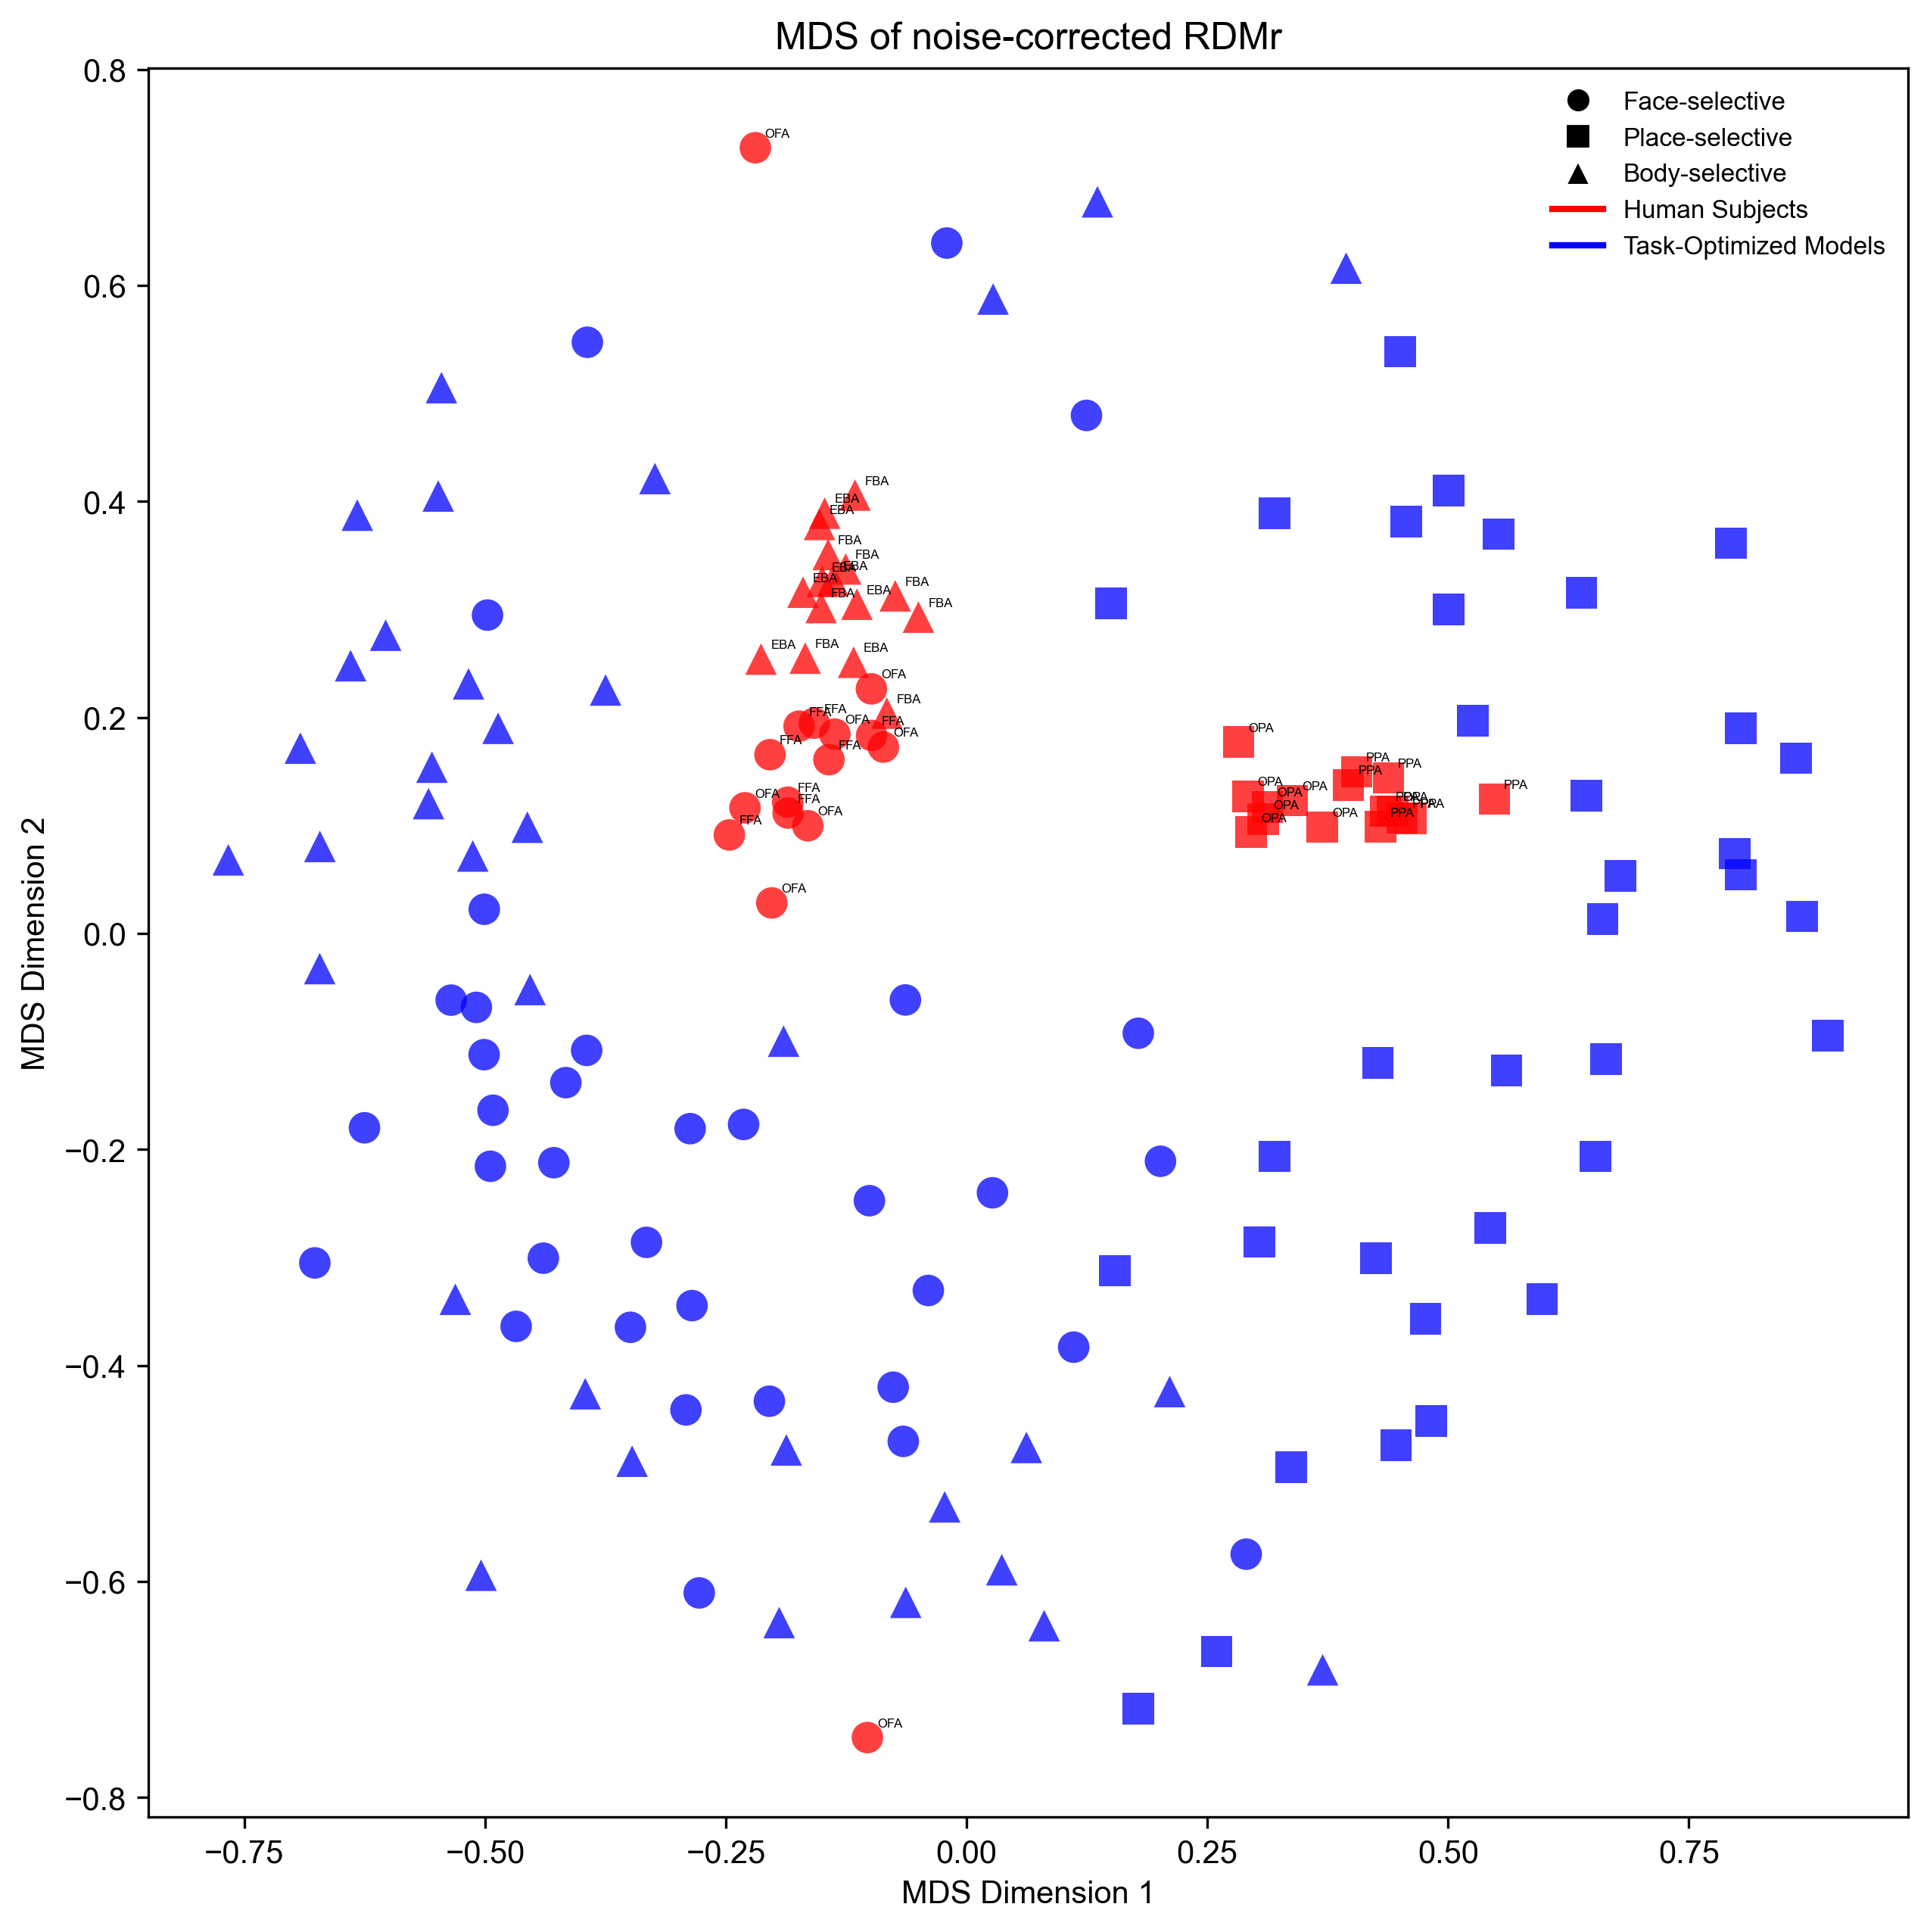

In [89]:
# Plot
savefig = False

# Decide marker types and colors
keys = list(ordered_responses.keys())
# Marker types: circle for face-sselective (FFA, OFA), square for place-selective (PPA, OPA), triangle for body-selective (EBA, FBA)
marker_types = []
for key in keys:
    if 'FFA' in key or 'OFA' in key:
        marker_types.append('o')  # Circle
    elif 'PPA' in key or 'OPA' in key:
        marker_types.append('s')  # Square
    elif 'EBA' in key or 'FBA' in key:
        marker_types.append('^')  # Triangle
    else:
        raise ValueError(f'Unknown froi in key: {key}')
        marker_types.append('x')  # Unknown, use x
# Colors: red for human subjects, blue for models
color_types = []
for key in keys:
    if key.startswith('subject_'):
        color_types.append('human')
    elif key.startswith('model_'):
        color_types.append('model')
    else:
        raise ValueError(f'Unknown system type in key: {key}')
        color_types.append('unknown')

# Also add the froi information as text labels on the points, with slight offsets only for human subjects
points_texts = []
for idx, key in enumerate(keys):
    if key.startswith('subject_'):
        if 'FFA' in key:
            froi_label = 'FFA'
        elif 'OFA' in key:
            froi_label = 'OFA'
        elif 'PPA' in key:
            froi_label = 'PPA'
        elif 'OPA' in key:
            froi_label = 'OPA'
        elif 'EBA' in key:
            froi_label = 'EBA'
        elif 'FBA' in key:
            froi_label = 'FBA'
        else:
            raise ValueError(f'Unknown froi in key: {key}')
            froi_label = 'Unknown'
    else:
        froi_label = ''
    points_texts.append(froi_label)

human_color = 'red'
model_color = 'blue'
facecolors = [mcolors.to_rgba(human_color, alpha=0.75) if key in range(1, 9) else mcolors.to_rgba(model_color, alpha=0.75) for key in keys]
plt.figure(figsize=(10, 10), dpi=300)
# Plot each point individually to set different markers
for i in range(len(keys)):
    if color_types[i] == 'human':
        point_color = human_color
    else:
        point_color = model_color
    plt.scatter(
        mds_coords[i, 0], mds_coords[i, 1],
        marker=marker_types[i],
        color=point_color,
        alpha=0.75,
        s=100,
        edgecolors='none',
        linewidths=2,
    )
# plt.scatter(mds_coords[:, 0], mds_coords[:, 1], fc=facecolors, ec='none', s=100, linewidths=2)
# Add text labels
for i, text in enumerate(points_texts):
    if text != '':
        if color_types[i] == 'human':
            plt.text(mds_coords[i, 0] + 0.01, mds_coords[i, 1] + 0.01, text, fontsize=4)
        else:
            plt.text(mds_coords[i, 0], mds_coords[i, 1], text, fontsize=8)
# Create custom legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Face-selective', markerfacecolor='k', markersize=8),
    Line2D([0], [0], marker='s', color='w', label='Place-selective', markerfacecolor='k', markersize=8),
    Line2D([0], [0], marker='^', color='w', label='Body-selective', markerfacecolor='k', markersize=8),
    Line2D([0], [0], linestyle='-', color=human_color, label='Human Subjects', linewidth=2),
    Line2D([0], [0], linestyle='-', color=model_color, label='Task-Optimized Models', linewidth=2),
]
plt.legend(handles=legend_elements, loc='best', fontsize=8, frameon=False)
plt.title('MDS of noise-corrected RDMr')
plt.xlabel('MDS Dimension 1')
plt.ylabel('MDS Dimension 2')
if savefig:
    plt.savefig(f'{plots_dir}/fig3_mds_normed_rdmr_t{tthreshold}.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()

In [ ]:
for metric in ['pearsonr', 'rdmr']:
    # Median
    model_froi = fmri_froi = 'median'
    print(f'Plotting MDS for {model_froi} and {fmri_froi}, metric: {metric}')
    mds_results = json.load(
        open(f'{results_dir}/noisecorrected_mds_results_{metric}_{model_froi}_{fmri_froi}.json')
    )
    mds_coords = np.array(mds_results['mds_coordinates'])
    keys = mds_results['keys']

    human_color = 'royalblue'
    model_color = 'red'
    facecolors = [mcolors.to_rgba(human_color, alpha=0.75) if key in range(1, 9) else mcolors.to_rgba(model_color, alpha=0.75) for key in keys]
    plt.figure(figsize=(5, 5), dpi=300)
    plt.scatter(mds_coords[:, 0], mds_coords[:, 1], fc=facecolors, ec='none', s=100, linewidths=2)

    annotate_models = False  # Set to True to annotate models, False to not annotate
    if annotate_models:
        for i, key in enumerate(keys):
            if key in froi_models_data:
                plt.annotate(key, (mds_coords[i, 0], mds_coords[i, 1]), fontsize=8)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.xticks([])
    plt.yticks([])
    # plt.xlabel('MDS Dimension 1')
    # plt.ylabel('MDS Dimension 2')
    # plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=human_color, markersize=10, label='Human'),
    #                     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=model_color, markersize=10, label='Model')],
    #         loc='best')
    # plt.title(f'{model_froi} and {fmri_froi}')
    plt.axis('off')
    plt.gcf().patch.set_alpha(0.0)
    plt.tight_layout()
    # plt.show()
    plt.savefig(f'{plots_dir}/mds_noisecorrected_{metric}_median_frois.pdf', dpi=300, bbox_inches='tight', transparent=True)
    plt.close()

# Individual frois
fig, axs = plt.subplots(2, len(model_fmri_frois), figsize=(5*len(model_fmri_frois), 5*2), dpi=300)
for midx, metric in enumerate(['pearsonr', 'rdmr']):
    for fidx, (model_froi, fmri_froi) in enumerate(model_fmri_frois):
        print(f'Plotting MDS for {model_froi} and {fmri_froi}, metric: {metric}')
        mds_results = json.load(
            open(f'{results_dir}/noisecorrected_mds_results_{metric}_{model_froi}_{fmri_froi}.json')
        )
        mds_coords = np.array(mds_results['mds_coordinates'])
        keys = mds_results['keys']

        human_color = 'royalblue'
        model_color = 'red'
        # colors = [human_color if key in froi_subjects_data else model_color for key in keys]
        facecolors = [mcolors.to_rgba(human_color, alpha=0.75) if key in range(1, 9) else mcolors.to_rgba(model_color, alpha=0.75) for key in keys]
        # edgecolors = [human_color if key in froi_subjects_data else model_color for key in keys]
        # edgecolors = ['white' if key in froi_subjects_data else 'white' for key in keys]
        # plt.scatter(mds_coords[:, 0], mds_coords[:, 1], c=colors, s=100)
        axs[midx, fidx].scatter(mds_coords[:, 0], mds_coords[:, 1], fc=facecolors, ec='none', s=100, linewidths=2)

        annotate_models = False  # Set to True to annotate models, False to not annotate
        if annotate_models:
            for i, key in enumerate(keys):
                if key in froi_models_data:
                    plt.annotate(key, (mds_coords[i, 0], mds_coords[i, 1]), fontsize=8)

        # axs[midx, fidx].spines['top'].set_visible(False)
        # axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].set_xticks([])
        axs[midx, fidx].set_yticks([])
        # plt.xlabel('MDS Dimension 1')
        # plt.ylabel('MDS Dimension 2')
        # plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=human_color, markersize=10, label='Human'),
        #                     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=model_color, markersize=10, label='Model')],
        #         loc='best')
        # axs[midx, fidx].set_title(f'{model_froi} and {fmri_froi}')
        axs[midx, fidx].axis('off')
        # Write froi name in bottom left corner
        axs[midx, fidx].text(0.9, 0.1, model_froi, transform=axs[midx, fidx].transAxes, fontsize=12, verticalalignment='top')
plt.gcf().patch.set_alpha(0.0)
plt.tight_layout()
# plt.show()
plt.savefig(f'{plots_dir}/mds_noisecorrected_pearsronr_rdmr_individual_frois.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.close()